# **PENGEMBANGAN DASHBOARD ANALITIK DATA INVENTARIS UNTUK MENDUKUNG PEMANTAUAN DAN EVALUASI ASET PADA PERUMDA AIR MINUM SURYA SEMBADA KOTA SURABAYA BERBASIS STREAMLIT**

### Proyek Konversi Mata Kuliah Kecerdasan Bisnis (SD221209)

Notebook disusun mengikuti alur kerja Business Intelligence: identifikasi masalah, pemahaman data, ETL, pemodelan data, analisis, reporting, evaluasi, dan persiapan implementasi dashboard Streamlit.

## 1. Identifikasi Permasalahan dan Tujuan Proyek

Dataset inventaris memuat informasi aset berdasarkan lokasi, bagian, kategori, kondisi, status, dan atribut pendukung lainnya. Data tersebut dapat dimanfaatkan untuk menghasilkan informasi yang membantu pengguna dari berbagai bagian memahami komposisi aset, membandingkan kondisi inventaris, mengidentifikasi konsentrasi aset bermasalah, serta mengevaluasi kelengkapan data.

**Rumusan masalah analitis:**
1. Bagaimana distribusi jumlah aset pada setiap lokasi dan bagian?
2. Bagaimana kondisi dan status aset jika dibandingkan berdasarkan lokasi, bagian, dan kategori?
3. Lokasi, bagian, atau jenis barang mana yang memberikan kontribusi terbesar terhadap aset bermasalah?
4. Seberapa lengkap atribut penting dalam data inventaris?
5. Informasi apa yang dapat disajikan sebagai bahan evaluasi dan tindak lanjut pengelolaan aset?

**Tujuan:** membangun dasar analitik yang dapat diterjemahkan menjadi dashboard interaktif. Analisis ini bersifat deskriptif dan evaluatif berdasarkan snapshot data yang tersedia, bukan pemantauan real-time.

## Keterkaitan Proyek dengan Kriteria Penilaian Konversi

Bagian ini melengkapi analisis inventaris dengan konsep dan rancangan yang berkaitan langsung dengan kriteria penilaian konversi Mata Kuliah Kecerdasan Bisnis. Implementasi dibedakan secara jelas antara proses yang benar-benar dilakukan pada notebook dan rancangan yang akan diwujudkan pada aplikasi Streamlit.

## Keterkaitan dengan Kriteria Lembar Konversi

| Kriteria penilaian konversi | Bukti dalam proyek |
|---|---|
| Konsep BI, ETL, data warehouse, model multidimensional, data mining, reporting dan visualisasi | Penjelasan konsep, proses ETL, rancangan star schema, dimensi analisis, serta visualisasi |
| Pemilihan metode dan pendekatan BI | EDA, descriptive analytics, comparative analysis, cross-tabulation, Pareto, dan data quality analysis |
| Bahasa pemrograman dan tools BI | Python, Pandas, NumPy, Matplotlib/Seaborn, serta implementasi dashboard dengan Streamlit |
| Perancangan BI workflow | Alur identifikasi masalah, penyediaan data, analisis, reporting, pengujian, dan deployment |

**Batas implementasi:** notebook ini melakukan pengolahan dan analisis data serta membangun rancangan model analitik. Data warehouse fisik, integrasi otomatis dengan MonInven, dan deployment dashboard merupakan tahap implementasi aplikasi lanjutan, bukan sesuatu yang diklaim telah selesai pada notebook.

## 1.1 Konsep Business Intelligence pada Studi Kasus Inventaris

Business Intelligence (BI) merupakan pendekatan untuk mengolah data menjadi informasi yang mendukung pemantauan, evaluasi, dan pengambilan keputusan. Dalam proyek ini, BI digunakan untuk mengubah data inventaris PDAM menjadi ringkasan dan insight berdasarkan lokasi, bagian, kategori, kondisi, serta status aset.

Komponen BI yang diterapkan atau dirancang:
1. **Data source:** file Excel inventaris sebagai sumber data awal.
2. **Data integration and preparation:** proses pemeriksaan, pembersihan, transformasi, dan penyusunan data.
3. **Data storage/modeling:** rancangan tabel fakta dan dimensi untuk kebutuhan analisis multidimensional.
4. **Analytics:** analisis deskriptif, komparatif, Pareto, dan kualitas data.
5. **Reporting and visualization:** penyajian KPI, grafik, tabel, filter, dan insight.
6. **Decision support:** informasi untuk membantu bagian terkait mengevaluasi kondisi dan persebaran aset.

Proyek ini merupakan dashboard analitik pelengkap. Proyek tidak menyatakan menggantikan aplikasi inventaris atau sistem MonInven yang sedang dikembangkan PDAM.

In [39]:
# IMPORT LIBRARY DAN PENGATURAN VISUALISASI

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from google.colab import files

# Palet warna utama: teal, navy, sage, amber, dan coral
COLORS = {
    "navy": "#243B53",
    "teal": "#2A9D8F",
    "sage": "#8AB17D",
    "amber": "#E9C46A",
    "coral": "#E76F51",
    "blue": "#577590",
    "light": "#F4F7F6",
    "gray": "#64748B",
    "dark": "#263238"
}

PALETTE = [
    COLORS["teal"], COLORS["blue"], COLORS["sage"],
    COLORS["amber"], COLORS["coral"], COLORS["navy"]
]

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font="DejaVu Sans",
    rc={
        "axes.facecolor": "#FFFFFF",
        "figure.facecolor": "#FFFFFF",
        "axes.edgecolor": "#D9E2EC",
        "grid.color": "#E8EEF2",
        "grid.linewidth": 0.8,
        "axes.titleweight": "bold",
        "axes.titlesize": 14,
        "axes.labelcolor": COLORS["dark"],
        "xtick.color": COLORS["gray"],
        "ytick.color": COLORS["gray"],
        "text.color": COLORS["dark"]
    }
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

def style_axis(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, loc="left", pad=14, color=COLORS["navy"], fontweight="bold")
    if xlabel:
        ax.set_xlabel(xlabel, labelpad=8)
    if ylabel:
        ax.set_ylabel(ylabel, labelpad=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D9E2EC")
    ax.spines["bottom"].set_color("#D9E2EC")
    ax.grid(axis="x", alpha=0.55)
    ax.set_axisbelow(True)

def add_bar_labels(ax, horizontal=False, fmt="{:,.0f}", padding=4):
    for patch in ax.patches:
        value = patch.get_width() if horizontal else patch.get_height()
        if pd.isna(value):
            continue
        if horizontal:
            ax.annotate(
                fmt.format(value),
                (patch.get_width(), patch.get_y() + patch.get_height()/2),
                xytext=(padding, 0), textcoords="offset points",
                va="center", ha="left", fontsize=9, color=COLORS["dark"]
            )
        else:
            ax.annotate(
                fmt.format(value),
                (patch.get_x() + patch.get_width()/2, patch.get_height()),
                xytext=(0, padding), textcoords="offset points",
                va="bottom", ha="center", fontsize=9, color=COLORS["dark"]
            )

## 2. Load Dataset dan Extract Data
Data sumber yang digunakan adalah sheet `Data_Inventaris` dari workbook inventaris PDAM. Tahap ini merupakan proses Extract dalam ETL.

In [40]:
uploaded = files.upload()
file_name = next(iter(uploaded))

df_raw = pd.read_excel(
    file_name,
    sheet_name="Data_Inventaris"
)

df_raw.columns = df_raw.columns.astype(str).str.strip()

print("Dataset berhasil dibaca.")
print(f"Jumlah baris  : {df_raw.shape[0]:,}")
print(f"Jumlah kolom  : {df_raw.shape[1]}")

display(df_raw.head())

Saving Data Inventaris PDAM.xlsx to Data Inventaris PDAM (1).xlsx
Dataset berhasil dibaca.
Jumlah baris  : 9,110
Jumlah kolom  : 16


,No.,Lokasi,Bagian,Kode Asset,Kategori,Nama Barang,Fungsi / Tipe,Merk,Ukuran / Spesifikasi,Warna,Bahan,Tahun Pembelian,Jumlah,Kondisi,Status,Penanggung Jawab (PIC)
0,1,Gedung Blok A Lantai III,Akuntansi,01-001-011/2026-01/5,Mebelair,Meja,Meja Manajer,Informa,1 Biro,Hitam,Kayu dan Kaca,-,1,Sudah Diperbaiki,Aktif,Manajer Akuntansi
1,2,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/4,Mebelair,Meja,Meja Pantry,Informa,1/4 Biro,Cokelat,Kayu,-,1,Bagus,Aktif,Manajer Akuntansi
2,3,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/5,Mebelair,Meja,Meja Pendukung Manajer,Custom,1 Biro,Cream Abu,Board Kayu,-,1,Bagus,Aktif,Manajer Akuntansi
3,4,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/6,Mebelair,Meja,Meja Pendukung Manajer,Custom,1/2 Biro,Cream Abu,Board Kayu,-,1,Bagus,Aktif,Manajer Akuntansi
4,5,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/7,Mebelair,Meja,Meja Pendukung Manajer,Custom,1/2 Biro,Cream Abu,Board Kayu,-,1,Sudah Diperbaiki,Aktif,Manajer Akuntansi


## 3. Data Understanding dan EDA Awal
Tahap ini memeriksa struktur, tipe data, atribut, kualitas awal, missing value, dan duplikasi sebelum transformasi.

In [41]:
print("Ukuran dataset:", df_raw.shape)

df_raw.info()

display(df_raw.describe(include="all").T)

Ukuran dataset: (9110, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9110 entries, 0 to 9109
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   No.                     9110 non-null   int64 
 1   Lokasi                  9110 non-null   object
 2   Bagian                  9110 non-null   object
 3   Kode Asset              9110 non-null   object
 4   Kategori                9110 non-null   object
 5   Nama Barang             9110 non-null   object
 6   Fungsi / Tipe           9110 non-null   object
 7   Merk                    9110 non-null   object
 8   Ukuran / Spesifikasi    9110 non-null   object
 9   Warna                   9110 non-null   object
 10  Bahan                   9110 non-null   object
 11  Tahun Pembelian         9110 non-null   object
 12  Jumlah                  9110 non-null   int64 
 13  Kondisi                 9110 non-null   object
 14  Status                  9110 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
No.,"9,110.00",NaN,NaN,NaN,"4,555.50","2,629.97",1.00,"2,278.25","4,555.50","6,832.75","9,110.00"
Lokasi,9110,31,Gedung Blok A Lantai II,753,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Bagian,9110,51,Produksi Karang Pilang,1401,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kode Asset,9110,9110,01-001-011/2026-01/5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kategori,9110,2,Mebelair,7562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nama Barang,9110,46,Kursi,2563,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fungsi / Tipe,9110,184,Kursi Staf,1147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Merk,9110,129,Informa,4321,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ukuran / Spesifikasi,9110,204,Tinggi,1930,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Warna,9110,111,Hitam,1520,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
dataset_information = pd.DataFrame({
    "Komponen": [
        "Nama dataset",
        "Sumber",
        "Jumlah data",
        "Jumlah variabel",
        "Periode data",
        "Unit analisis",
        "Target analisis"
    ],
    "Keterangan": [
        "Data Inventaris Aset Perumda Air Minum Surya Sembada Kota Surabaya",
        "Data inventaris internal PDAM",
        f"{len(df_raw):,} baris",
        f"{len(df_raw.columns)} variabel",
        "Periode pencatatan perlu dikonfirmasi kepada pengelola data",
        "Aset inventaris",
        "Analisis kondisi, status, dan prioritas pemantauan aset"
    ]
})

display(dataset_information)

,Komponen,Keterangan
0,Nama dataset,Data Inventaris Aset Perumda Air Minum Surya Sembada Kota Surabaya
1,Sumber,Data inventaris internal PDAM
2,Jumlah data,"9,110 baris"
3,Jumlah variabel,16 variabel
4,Periode data,Periode pencatatan perlu dikonfirmasi kepada pengelola data
5,Unit analisis,Aset inventaris
6,Target analisis,"Analisis kondisi, status, dan prioritas pemantauan aset"


In [43]:
data_dictionary = pd.DataFrame([
    ["No.", "Integer", "Nomor urut pencatatan", "Identifier teknis"],
    ["Lokasi", "Categorical", "Lokasi penempatan aset", "Variabel analisis"],
    ["Bagian", "Categorical", "Bagian pengguna atau unit terkait", "Variabel analisis"],
    ["Kode Asset", "String", "Kode identifikasi aset", "Identifier"],
    ["Kategori", "Categorical", "Kategori aset", "Variabel analisis"],
    ["Nama Barang", "String", "Nama aset inventaris", "Deskripsi"],
    ["Fungsi / Tipe", "Categorical", "Fungsi atau tipe aset", "Deskripsi"],
    ["Merk", "Categorical", "Merek aset", "Deskripsi"],
    ["Ukuran / Spesifikasi", "String", "Ukuran atau spesifikasi aset", "Deskripsi"],
    ["Warna", "Categorical", "Warna aset", "Deskripsi"],
    ["Bahan", "Categorical", "Bahan pembentuk aset", "Deskripsi"],
    ["Tahun Pembelian", "Numerik", "Tahun pembelian aset", "Kandidat fitur"],
    ["Jumlah", "Integer", "Jumlah aset pada baris pencatatan", "Dasar agregasi"],
    ["Kondisi", "Categorical", "Kondisi fisik aset", "Variabel utama"],
    ["Status", "Categorical", "Status aktif atau tidak aktif", "Variabel analisis"],
    ["Penanggung Jawab (PIC)", "Categorical", "Pihak yang bertanggung jawab", "Informasi pendukung"]
], columns=["Variabel", "Tipe Konseptual", "Deskripsi", "Peran"])

display(data_dictionary)

,Variabel,Tipe Konseptual,Deskripsi,Peran
0,No.,Integer,Nomor urut pencatatan,Identifier teknis
1,Lokasi,Categorical,Lokasi penempatan aset,Variabel analisis
2,Bagian,Categorical,Bagian pengguna atau unit terkait,Variabel analisis
3,Kode Asset,String,Kode identifikasi aset,Identifier
4,Kategori,Categorical,Kategori aset,Variabel analisis
5,Nama Barang,String,Nama aset inventaris,Deskripsi
6,Fungsi / Tipe,Categorical,Fungsi atau tipe aset,Deskripsi
7,Merk,Categorical,Merek aset,Deskripsi
8,Ukuran / Spesifikasi,String,Ukuran atau spesifikasi aset,Deskripsi
9,Warna,Categorical,Warna aset,Deskripsi


In [44]:
missing_summary = pd.DataFrame({
    "Jumlah Kosong": df_raw.isna().sum(),
    "Persentase Kosong (%)": (
        df_raw.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Persentase Kosong (%)",
        ascending=False
    )
)

,Jumlah Kosong,Persentase Kosong (%)
No.,0,0.00
Lokasi,0,0.00
Bagian,0,0.00
Kode Asset,0,0.00
Kategori,0,0.00
Nama Barang,0,0.00
Fungsi / Tipe,0,0.00
Merk,0,0.00
Ukuran / Spesifikasi,0,0.00
Warna,0,0.00


In [45]:
missing_markers = ["-", ""]

marker_summary = []

for col in df_raw.select_dtypes(include=["object", "string"]).columns:
    values = df_raw[col].astype("string").str.strip()

    marker_summary.append({
        "Variabel": col,
        "Jumlah Penanda Kosong": int(
            values.isin(missing_markers).sum()
        )
    })

display(
    pd.DataFrame(marker_summary).sort_values(
        "Jumlah Penanda Kosong",
        ascending=False
    )
)

,Variabel,Jumlah Penanda Kosong
10,Tahun Pembelian,8197
9,Bahan,1983
6,Merk,124
7,Ukuran / Spesifikasi,92
8,Warna,2
0,Lokasi,0
5,Fungsi / Tipe,0
4,Nama Barang,0
3,Kategori,0
2,Kode Asset,0


In [46]:
print("Jumlah baris duplikat:", df_raw.duplicated().sum())

if "Kode Asset" in df_raw.columns:
    valid_codes = df_raw["Kode Asset"].dropna().astype(str).str.strip()

    print(
        "Jumlah kode aset berulang:",
        int(valid_codes.duplicated().sum())
    )

    duplicate_codes = df_raw[
        df_raw["Kode Asset"].notna()
        & df_raw["Kode Asset"].astype(str).str.strip().duplicated(keep=False)
    ].sort_values("Kode Asset")

    display(duplicate_codes.head(20))

Jumlah baris duplikat: 0
Jumlah kode aset berulang: 0


,No.,Lokasi,Bagian,Kode Asset,Kategori,Nama Barang,Fungsi / Tipe,Merk,Ukuran / Spesifikasi,Warna,Bahan,Tahun Pembelian,Jumlah,Kondisi,Status,Penanggung Jawab (PIC)


In [47]:
categorical_columns = df_raw.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_columns = df_raw.select_dtypes(
    include=np.number
).columns.tolist()

print("Variabel kategorikal:")
print(categorical_columns)

print("\nVariabel numerik:")
print(numerical_columns)

for col in [
    "Lokasi", "Bagian", "Kategori",
    "Kondisi", "Status"
]:
    if col in df_raw.columns:
        print(f"\nDistribusi {col}:")
        display(
            df_raw[col].value_counts(dropna=False).rename_axis(col).reset_index(name="Frekuensi")
        )

Variabel kategorikal:
['Lokasi', 'Bagian', 'Kode Asset', 'Kategori', 'Nama Barang', 'Fungsi / Tipe', 'Merk', 'Ukuran / Spesifikasi', 'Warna', 'Bahan', 'Tahun Pembelian', 'Kondisi', 'Status', 'Penanggung Jawab (PIC)']

Variabel numerik:
['No.', 'Jumlah']

Distribusi Lokasi:


,Lokasi,Frekuensi
0,Gedung Blok A Lantai II,753
1,IPAM Ngagel I,738
2,Gedung Blok A Lantai III,568
3,IPAM Ngagel II,509
4,Gedung Blok A Lantai IV,498
5,IPAM Karangpilang I,492
6,Gedung Blok B Lantai I,490
7,IPAM Karangpilang II,450
8,Gedung Blok B Lantai II,447
9,Gudang Ratna,432



Distribusi Bagian:


,Bagian,Frekuensi
0,Produksi Karang Pilang,1401
1,Produksi Ngagel,1369
2,Layanan Internal,1251
3,Logistik,539
4,Hubungan Pelanggan,447
5,Akuntansi,417
6,Kelola Aset Properti,288
7,Sistem Transmisi dan Distribusi Utama,232
8,Pelayanan Teknis Timur,202
9,Rekening dan Pembayaran,198



Distribusi Kategori:


,Kategori,Frekuensi
0,Mebelair,7562
1,Elektronik,1548



Distribusi Kondisi:


,Kondisi,Frekuensi
0,Bagus,6559
1,Kurang Baik,1093
2,Dalam Perbaikan,546
3,Sudah Diperbaiki,457
4,Rusak,455



Distribusi Status:


,Status,Frekuensi
0,Aktif,9057
1,Tidak Aktif,53


## 4. Data Cleaning dan Transformasi (ETL)
Data dibersihkan melalui standardisasi teks, konversi tipe data, dan penanganan penanda nilai kosong. Proses ini merupakan tahap Transform dalam ETL.

In [48]:
df_clean = df_raw.copy()

df_clean.columns = df_clean.columns.astype(str).str.strip()

text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

print("Data sumber:", df_raw.shape)
print("Data hasil salinan:", df_clean.shape)

Data sumber: (9110, 16)
Data hasil salinan: (9110, 16)


In [49]:
for col in ["No.", "Jumlah"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col],
            errors="coerce"
        ).astype("Int64")

if "Tahun Pembelian" in df_clean.columns:
    year_values = (
        df_clean["Tahun Pembelian"]
        .astype("string")
        .str.strip()
        .replace({"-": pd.NA, "": pd.NA})
    )

    df_clean["Tahun Pembelian"] = pd.to_numeric(
        year_values,
        errors="coerce"
    )

print("Tipe data setelah transformasi:")
display(
    pd.DataFrame({
        "Tipe Data": df_clean.dtypes.astype(str),
        "Jumlah Kosong": df_clean.isna().sum()
    })
)

Tipe data setelah transformasi:


,Tipe Data,Jumlah Kosong
No.,Int64,0
Lokasi,string,0
Bagian,string,0
Kode Asset,string,0
Kategori,string,0
Nama Barang,string,0
Fungsi / Tipe,string,0
Merk,string,0
Ukuran / Spesifikasi,string,0
Warna,string,0


In [50]:
transformation_evaluation = pd.DataFrame({
    "Metrik": [
        "Jumlah baris sebelum",
        "Jumlah baris sesudah",
        "Jumlah kolom sebelum",
        "Jumlah kolom sesudah",
        "Jumlah missing value sebelum",
        "Jumlah missing value sesudah"
    ],
    "Nilai": [
        len(df_raw),
        len(df_clean),
        len(df_raw.columns),
        len(df_clean.columns),
        int(df_raw.isna().sum().sum()),
        int(df_clean.isna().sum().sum())
    ]
})

display(transformation_evaluation)

,Metrik,Nilai
0,Jumlah baris sebelum,9110
1,Jumlah baris sesudah,9110
2,Jumlah kolom sebelum,16
3,Jumlah kolom sesudah,16
4,Jumlah missing value sebelum,0
5,Jumlah missing value sesudah,8197


## 4.1 ETL Process: Extract, Transform, Load

ETL merupakan tahapan pemindahan dan penyiapan data dari sumber agar dapat digunakan untuk analisis. Pada proyek ini, proses ETL dilakukan terhadap file Excel inventaris.

- **Extract:** membaca sheet `Data_Inventaris` dari file Excel.
- **Transform:** menstandarkan nama kolom dan teks, menangani penanda kosong, mengonversi kolom jumlah, serta membentuk indikator analisis.
- **Load:** menyimpan hasil transformasi ke file keluaran yang dapat digunakan kembali oleh dashboard.

Tahap Load pada notebook ini menghasilkan file analitik lokal (CSV). Ini belum merupakan implementasi enterprise data warehouse atau koneksi otomatis ke sistem PDAM.

In [51]:
# ETL: TRANSFORM DAN LOAD DATA ANALITIK

# Gunakan data hasil pembersihan dari tahapan sebelumnya
etl_data = df_clean.copy()
etl_data.columns = etl_data.columns.astype(str).str.strip()

# Transformasi tipe data dan penanda nilai kosong
if "Jumlah" in etl_data.columns:
    etl_data["Jumlah"] = pd.to_numeric(etl_data["Jumlah"], errors="coerce").fillna(0)

for col in etl_data.select_dtypes(include=["object", "string"]).columns:
    etl_data[col] = (
        etl_data[col].astype("string").str.strip()
        .replace({"": pd.NA, "-": pd.NA})
    )

# Membentuk indikator aset bermasalah dengan definisi yang digunakan pada analisis
if {"Jumlah", "Kondisi"}.issubset(etl_data.columns):
    problem_conditions = ["Kurang Baik", "Dalam Perbaikan", "Rusak"]
    etl_data["Aset_Bermasalah"] = np.where(
        etl_data["Kondisi"].isin(problem_conditions),
        etl_data["Jumlah"],
        0
    )

# Pemeriksaan hasil transformasi
print("Ukuran data hasil transformasi:", etl_data.shape)
print("Total unit aset:", f"{etl_data['Jumlah'].sum():,.0f}" if "Jumlah" in etl_data else "Kolom Jumlah tidak tersedia")
display(etl_data.head())

# LOAD: simpan dataset analitik yang telah ditransformasi
etl_output_path = "data_inventaris_analitik.csv"
etl_data.to_csv(etl_output_path, index=False, encoding="utf-8-sig")
print(f"File hasil ETL tersimpan: {etl_output_path}")

# Unduh file hasil ETL dari Google Colab
files.download(etl_output_path)

Ukuran data hasil transformasi: (9110, 17)
Total unit aset: 9,110


,No.,Lokasi,Bagian,Kode Asset,Kategori,Nama Barang,Fungsi / Tipe,Merk,Ukuran / Spesifikasi,Warna,Bahan,Tahun Pembelian,Jumlah,Kondisi,Status,Penanggung Jawab (PIC),Aset_Bermasalah
0,1,Gedung Blok A Lantai III,Akuntansi,01-001-011/2026-01/5,Mebelair,Meja,Meja Manajer,Informa,1 Biro,Hitam,Kayu dan Kaca,<NA>,1,Sudah Diperbaiki,Aktif,Manajer Akuntansi,0
1,2,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/4,Mebelair,Meja,Meja Pantry,Informa,1/4 Biro,Cokelat,Kayu,<NA>,1,Bagus,Aktif,Manajer Akuntansi,0
2,3,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/5,Mebelair,Meja,Meja Pendukung Manajer,Custom,1 Biro,Cream Abu,Board Kayu,<NA>,1,Bagus,Aktif,Manajer Akuntansi,0
3,4,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/6,Mebelair,Meja,Meja Pendukung Manajer,Custom,1/2 Biro,Cream Abu,Board Kayu,<NA>,1,Bagus,Aktif,Manajer Akuntansi,0
4,5,Gedung Blok A Lantai III,Akuntansi,01-001-012/2026-01/7,Mebelair,Meja,Meja Pendukung Manajer,Custom,1/2 Biro,Cream Abu,Board Kayu,<NA>,1,Sudah Diperbaiki,Aktif,Manajer Akuntansi,0


File hasil ETL tersimpan: data_inventaris_analitik.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4.2 Rancangan Data Warehouse dan Model Multidimensional

Untuk mendukung analisis lintas bagian, lokasi, kategori, kondisi, dan status, data dapat dimodelkan secara dimensional. Rancangan awal menggunakan pendekatan **star schema** dengan satu tabel fakta inventaris dan beberapa tabel dimensi.

### Rancangan Star Schema

**Fact_Inventory**
- `Jumlah`: kuantitas aset yang tercatat.
- `Kode Asset`: identitas aset pada sumber (dipertahankan sebagai business key).
- Foreign key menuju dimensi lokasi, bagian, kategori, kondisi, dan status.

**Tabel dimensi**
- `Dim_Lokasi`: lokasi aset.
- `Dim_Bagian`: bagian pemilik/pengguna aset.
- `Dim_Kategori`: kategori dan nama barang.
- `Dim_Kondisi`: kondisi aset.
- `Dim_Status`: status aset.

Model multidimensional memungkinkan data dianalisis melalui perspektif yang berbeda, misalnya jumlah aset menurut bagian dan kondisi, atau aset bermasalah menurut lokasi dan kategori.

**Catatan:** rancangan ini merupakan model konseptual/logis untuk kebutuhan reporting. Implementasi data warehouse fisik memerlukan penetapan grain, primary key, foreign key, aturan historisasi, serta proses pembaruan data bersama pengelola sistem.

In [52]:
# PEMBENTUKAN PROTOTIPE TABEL FAKTA DAN DIMENSI

# Kolom dimensi disesuaikan dengan atribut yang tersedia pada dataset
dimension_candidates = {
    "Dim_Lokasi": ["Lokasi"],
    "Dim_Bagian": ["Bagian"],
    "Dim_Kategori": ["Kategori", "Nama Barang"],
    "Dim_Kondisi": ["Kondisi"],
    "Dim_Status": ["Status"]
}

warehouse_source = etl_data.copy()
dimension_tables = {}
key_map = {}

# Membentuk tabel dimensi dengan surrogate key sederhana
for dim_name, cols in dimension_candidates.items():
    available_cols = [c for c in cols if c in warehouse_source.columns]
    if not available_cols:
        continue

    dim = (
        warehouse_source[available_cols]
        .drop_duplicates()
        .reset_index(drop=True)
    )
    key_col = dim_name.replace("Dim_", "ID_")
    dim.insert(0, key_col, np.arange(1, len(dim) + 1))
    dimension_tables[dim_name] = dim

    merge_key = available_cols
    warehouse_source = warehouse_source.merge(
        dim,
        on=merge_key,
        how="left"
    )
    key_map[dim_name] = key_col

# Membentuk tabel fakta dengan foreign key dimensi dan ukuran kuantitatif
fact_columns = [c for c in key_map.values() if c in warehouse_source.columns]
if "Jumlah" in warehouse_source.columns:
    fact_columns.append("Jumlah")
if "Kode Asset" in warehouse_source.columns:
    fact_columns.append("Kode Asset")

fact_inventory = warehouse_source[fact_columns].copy()

print("Tabel fakta inventaris:")
display(fact_inventory.head())

print("Tabel dimensi:")
for name, table in dimension_tables.items():
    print(name, table.shape)
    display(table.head())

print("Catatan: tabel ini merupakan prototipe model dimensional dari snapshot data, bukan data warehouse produksi.")

Tabel fakta inventaris:


,ID_Lokasi,ID_Bagian,ID_Kategori,ID_Kondisi,ID_Status,Jumlah,Kode Asset
0,1,1,1,1,1,1,01-001-011/2026-01/5
1,1,1,1,2,1,1,01-001-012/2026-01/4
2,1,1,1,2,1,1,01-001-012/2026-01/5
3,1,1,1,2,1,1,01-001-012/2026-01/6
4,1,1,1,1,1,1,01-001-012/2026-01/7


Tabel dimensi:
Dim_Lokasi (31, 2)


,ID_Lokasi,Lokasi
0,1,Gedung Blok A Lantai III
1,2,Gedung Blok A Lantai II
2,3,Gedung Blok A Lantai IV
3,4,Gedung Blok B Lantai I
4,5,Gedung Blok C Lantai I


Dim_Bagian (51, 2)


,ID_Bagian,Bagian
0,1,Akuntansi
1,2,Anggaran dan Kas
2,3,Direktorat Keuangan
3,4,Direktorat Operasi
4,5,Direktorat Pelayanan


... (3 outputs left out)

,ID_Kondisi,Kondisi
0,1,Sudah Diperbaiki
1,2,Bagus
2,3,Rusak
3,4,Kurang Baik
4,5,Dalam Perbaikan


Dim_Status (2, 2)


,ID_Status,Status
0,1,Aktif
1,2,Tidak Aktif


Catatan: tabel ini merupakan prototipe model dimensional dari snapshot data, bukan data warehouse produksi.


## 5. Analisis Deskriptif dan Visualisasi Data
Setelah data disiapkan, dilakukan analisis distribusi kategori, kondisi, status, dan persebaran lokasi sebagai gambaran umum inventaris.

## **Visualisasi Distribusi Kategori**
Grafik ini membandingkan jumlah unit aset pada setiap kategori. Label nilai ditampilkan agar perbedaan jumlah dapat dibaca tanpa memperkirakan panjang batang.

,Kategori,Jumlah
0,Mebelair,7562
1,Elektronik,1548


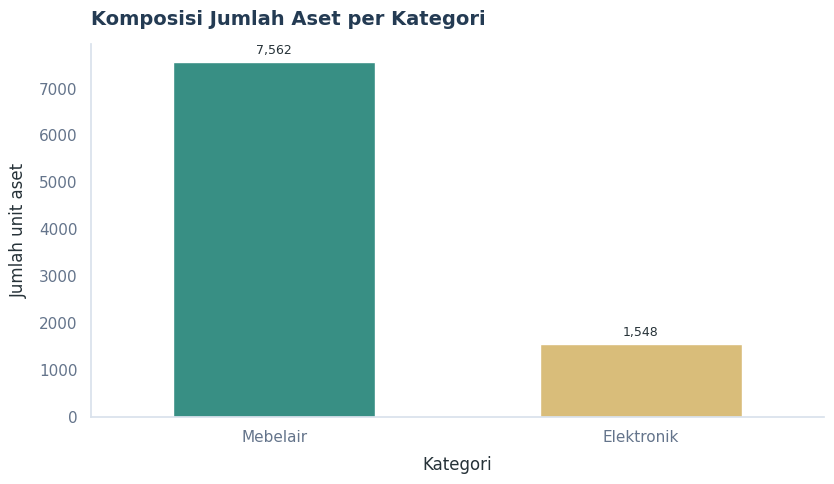

In [53]:
# DISTRIBUSI JUMLAH ASET BERDASARKAN KATEGORI

category_summary = (
    df_clean.groupby("Kategori", dropna=False)["Jumlah"]
    .sum().sort_values(ascending=False).reset_index()
)
display(category_summary)

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.barplot(
    data=category_summary, x="Kategori", y="Jumlah",
    hue="Kategori", palette=[COLORS["teal"], COLORS["amber"]],
    legend=False, ax=ax, width=0.55
)
style_axis(ax, "Komposisi Jumlah Aset per Kategori", "Kategori", "Jumlah unit aset")
add_bar_labels(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.show()

## **Visualisasi Kondisi Aset**
Warna digunakan secara konsisten untuk membedakan kondisi: teal untuk kondisi baik, amber untuk kondisi yang perlu perhatian, dan coral untuk kondisi rusak.

,Kondisi,Jumlah
0,Bagus,6559
1,Kurang Baik,1093
2,Dalam Perbaikan,546
3,Sudah Diperbaiki,457
4,Rusak,455


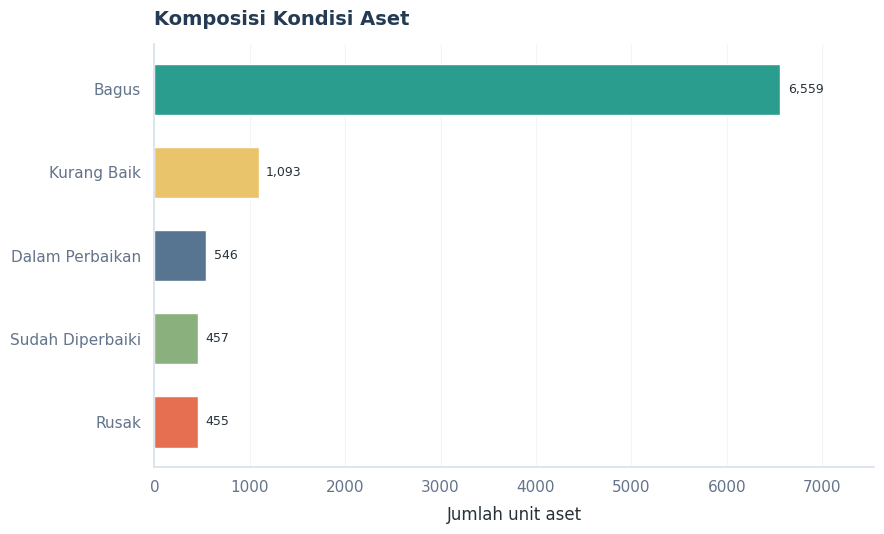

In [54]:
# DISTRIBUSI KONDISI ASET

condition_summary = (
    df_clean.groupby("Kondisi", dropna=False)["Jumlah"]
    .sum().sort_values(ascending=False).reset_index()
)
display(condition_summary)

condition_colors = {
    "Bagus": COLORS["teal"],
    "Sudah Diperbaiki": COLORS["sage"],
    "Kurang Baik": COLORS["amber"],
    "Dalam Perbaikan": COLORS["blue"],
    "Rusak": COLORS["coral"]
}
bar_colors = [condition_colors.get(x, COLORS["gray"]) for x in condition_summary["Kondisi"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(condition_summary["Kondisi"], condition_summary["Jumlah"], color=bar_colors, height=0.62)
style_axis(ax, "Komposisi Kondisi Aset", "Jumlah unit aset", None)
ax.invert_yaxis()
for bar in bars:
    ax.text(bar.get_width() + condition_summary["Jumlah"].max()*0.012,
            bar.get_y() + bar.get_height()/2, f"{bar.get_width():,.0f}",
            va="center", fontsize=9, color=COLORS["dark"])
ax.grid(axis="y", visible=False)
ax.set_xlim(0, condition_summary["Jumlah"].max()*1.15)
plt.tight_layout()
plt.show()

### **Pie Chart Komposisi Kondisi Aset**

Pie chart berikut menunjukkan proporsi setiap kondisi aset berdasarkan jumlah unit yang tercatat. Visualisasi menggunakan kategori kondisi yang sama dengan tabel distribusi: Bagus, Kurang Baik, Dalam Perbaikan, Sudah Diperbaiki, dan Rusak.

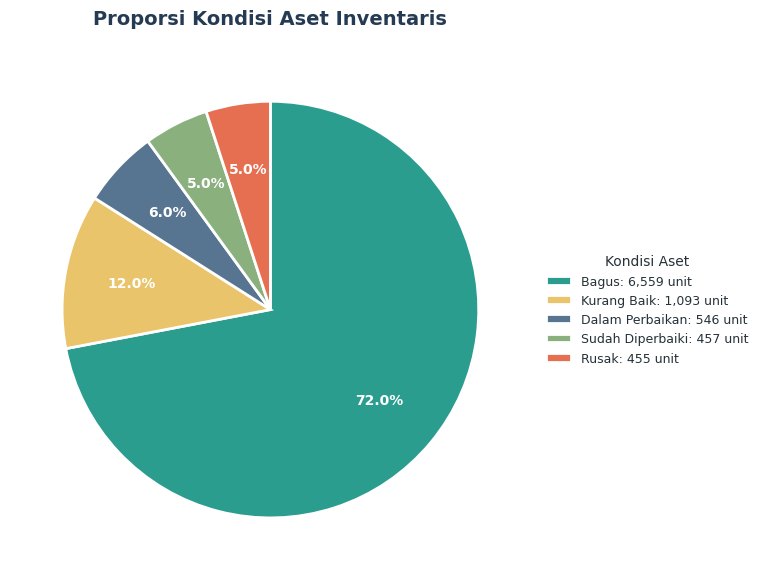

,Kondisi,Jumlah,Persentase (%)
0,Bagus,6559,72.00
1,Kurang Baik,1093,12.00
2,Dalam Perbaikan,546,5.99
3,Sudah Diperbaiki,457,5.02
4,Rusak,455,4.99


In [55]:
# PIE CHART DISTRIBUSI KONDISI ASET

condition_pie = (
    df_clean.groupby("Kondisi", dropna=False)["Jumlah"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

condition_pie["Persentase (%)"] = (
    condition_pie["Jumlah"] / condition_pie["Jumlah"].sum() * 100
)

condition_colors = {
    "Bagus": COLORS["teal"],
    "Kurang Baik": COLORS["amber"],
    "Dalam Perbaikan": COLORS["blue"],
    "Sudah Diperbaiki": COLORS["sage"],
    "Rusak": COLORS["coral"]
}
pie_colors = [
    condition_colors.get(str(kondisi).strip(), COLORS["gray"])
    for kondisi in condition_pie["Kondisi"]
]

fig, ax = plt.subplots(figsize=(10, 6.2))
wedges, texts, autotexts = ax.pie(
    condition_pie["Jumlah"],
    startangle=90,
    counterclock=False,
    colors=pie_colors,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
    pctdistance=0.68,
    textprops={"color": "white", "fontsize": 10, "fontweight": "bold"},
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

legend_labels = [
    f"{row['Kondisi']}: {row['Jumlah']:,.0f} unit"
    for _, row in condition_pie.iterrows()
]
ax.legend(
    wedges, legend_labels,
    title="Kondisi Aset",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=10,
    borderaxespad=0
)
ax.set_title(
    "Proporsi Kondisi Aset Inventaris",
    loc="center", pad=18,
    color=COLORS["navy"], fontweight="bold", fontsize=14
)
ax.set_aspect("equal")
fig.subplots_adjust(left=0.04, right=0.70, top=0.90, bottom=0.06)
plt.show()

display(condition_pie)

## **Visualisasi Status Aset**

Perbandingan status aset menggunakan dua panel dengan rentang sumbu berbeda. Panel utama menampilkan skala penuh, sedangkan panel bawah memperbesar rentang jumlah yang kecil agar kategori **Tidak Aktif** tetap terlihat. Nilai jumlah dan persentasenya ditampilkan agar pembaca tidak salah menafsirkan perbedaan skala.

,Status,Jumlah,Persentase (%)
0,Aktif,9057,99.42
1,Tidak Aktif,53,0.58


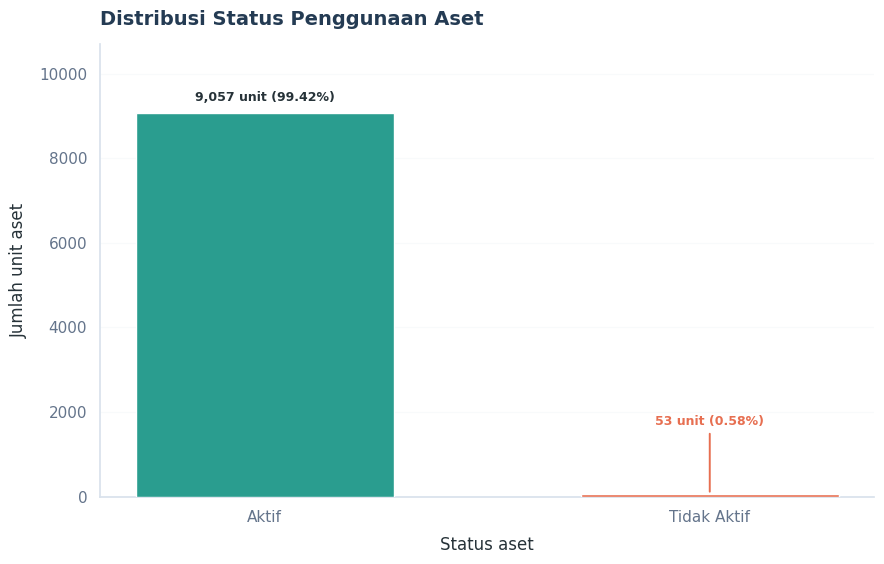

Sumbu menggunakan skala linear normal. Label kategori dengan jumlah kecil ditunjukkan melalui anotasi tanpa mengubah tinggi batang.


In [56]:
# DISTRIBUSI STATUS ASET

status_summary = (
    df_clean.groupby("Status", dropna=False)["Jumlah"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

total_status = status_summary["Jumlah"].sum()
status_summary["Persentase (%)"] = (
    status_summary["Jumlah"] / total_status * 100
    if total_status else 0
)
display(status_summary)

status_colors = {
    "Aktif": COLORS["teal"],
    "Tidak Aktif": COLORS["coral"],
    "Non Aktif": COLORS["coral"],
    "Nonaktif": COLORS["coral"]
}
bar_colors = [
    status_colors.get(str(status).strip(), COLORS["blue"])
    for status in status_summary["Status"]
]

fig, ax = plt.subplots(figsize=(9, 5.8))
x = np.arange(len(status_summary))
values = status_summary["Jumlah"].to_numpy()

bars = ax.bar(
    x, values, color=bar_colors,
    width=0.58, edgecolor="white", zorder=3
)
style_axis(ax, "Distribusi Status Penggunaan Aset", "Status aset", "Jumlah unit aset")
ax.set_xticks(x)
ax.set_xticklabels(status_summary["Status"])
ax.set_ylim(0, max(values) * 1.18 if len(values) else 1)
ax.grid(axis="y", alpha=0.28)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

for bar, (_, row) in zip(bars, status_summary.iterrows()):
    value = row["Jumlah"]
    percentage = row["Persentase (%)"]
    is_small = value <= max(values) * 0.10 if len(values) else False

    if is_small:
        # Label ditempatkan di atas batang dengan garis penunjuk; tinggi batang tetap memakai skala asli.
        ax.annotate(
            f"{value:,.0f} unit ({percentage:.2f}%)",
            xy=(bar.get_x() + bar.get_width()/2, value),
            xytext=(bar.get_x() + bar.get_width()/2, max(values) * 0.18),
            ha="center", va="bottom",
            fontsize=9, fontweight="bold", color=COLORS["coral"],
            arrowprops={"arrowstyle": "-", "color": COLORS["coral"], "lw": 1.4}
        )
    else:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + max(values)*0.025,
            f"{value:,.0f} unit ({percentage:.2f}%)",
            ha="center", va="bottom",
            fontsize=9, fontweight="bold", color=COLORS["dark"]
        )

plt.tight_layout()
plt.show()

print("Sumbu menggunakan skala linear normal. Label kategori dengan jumlah kecil ditunjukkan melalui anotasi tanpa mengubah tinggi batang.")

## **Visualisasi Persebaran Lokasi**
Grafik horizontal dipilih agar nama lokasi tetap mudah dibaca dan peringkat jumlah aset terlihat jelas.

,Lokasi,Jumlah
0,Gedung Blok A Lantai II,753
1,IPAM Ngagel I,738
2,Gedung Blok A Lantai III,568
3,IPAM Ngagel II,509
4,Gedung Blok A Lantai IV,498
5,IPAM Karangpilang I,492
6,Gedung Blok B Lantai I,490
7,IPAM Karangpilang II,450
8,Gedung Blok B Lantai II,447
9,Gudang Ratna,432


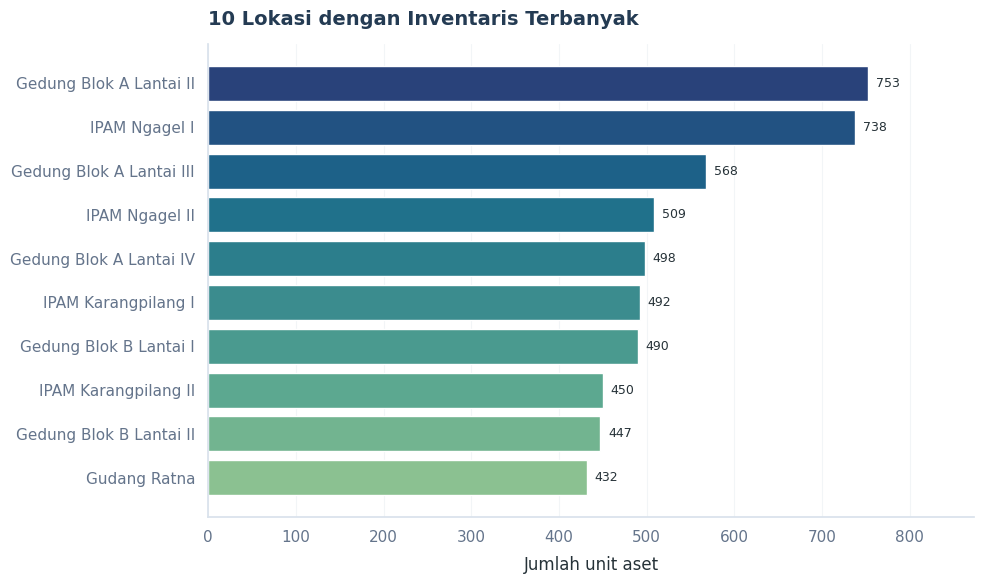

In [57]:
# SEPULUH LOKASI DENGAN JUMLAH ASET TERBANYAK

location_summary = (
    df_clean.groupby("Lokasi", dropna=False)["Jumlah"]
    .sum().sort_values(ascending=False).head(10).reset_index()
)
display(location_summary)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(location_summary["Lokasi"][::-1], location_summary["Jumlah"][::-1],
               color=sns.color_palette("crest", n_colors=len(location_summary)))
style_axis(ax, "10 Lokasi dengan Inventaris Terbanyak", "Jumlah unit aset", None)
for bar in bars:
    ax.text(bar.get_width() + location_summary["Jumlah"].max()*0.012,
            bar.get_y() + bar.get_height()/2, f"{bar.get_width():,.0f}",
            va="center", fontsize=9, color=COLORS["dark"])
ax.set_xlim(0, location_summary["Jumlah"].max()*1.16)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6. Analisis Kondisi, Status, dan Prioritas Lokasi
Analisis ini membentuk indikator aset bermasalah, menghitung problem rate, serta membandingkan jumlah dan proporsi aset bermasalah antar lokasi.

In [58]:
problem_conditions = [
    "Kurang Baik",
    "Dalam Perbaikan",
    "Rusak"
]

df_analysis = df_clean.copy()

df_analysis["Is_Problem"] = (
    df_analysis["Kondisi"]
    .isin(problem_conditions)
    .astype(int)
)

df_analysis["Is_Damaged"] = (
    df_analysis["Kondisi"]
    .eq("Rusak")
    .astype(int)
)

df_analysis["Is_Inactive"] = (
    df_analysis["Status"]
    .eq("Tidak Aktif")
    .astype(int)
)

display(
    df_analysis[
        [
            "Kode Asset",
            "Kondisi",
            "Status",
            "Is_Problem",
            "Is_Damaged",
            "Is_Inactive"
        ]
    ].head(10)
)

,Kode Asset,Kondisi,Status,Is_Problem,Is_Damaged,Is_Inactive
0,01-001-011/2026-01/5,Sudah Diperbaiki,Aktif,0,0,0
1,01-001-012/2026-01/4,Bagus,Aktif,0,0,0
2,01-001-012/2026-01/5,Bagus,Aktif,0,0,0
3,01-001-012/2026-01/6,Bagus,Aktif,0,0,0
4,01-001-012/2026-01/7,Sudah Diperbaiki,Aktif,0,0,0
5,01-001-015/2026-01/10,Bagus,Aktif,0,0,0
6,01-001-015/2026-01/11,Rusak,Aktif,1,1,0
7,01-001-015/2026-01/9,Bagus,Aktif,0,0,0
8,01-001-016/2026-01/10,Bagus,Aktif,0,0,0
9,01-001-016/2026-01/9,Rusak,Aktif,1,1,0


In [59]:
total_assets = df_analysis["Jumlah"].sum()

problem_assets = df_analysis.loc[
    df_analysis["Is_Problem"].eq(1), "Jumlah"
].sum()

damaged_assets = df_analysis.loc[
    df_analysis["Is_Damaged"].eq(1), "Jumlah"
].sum()

inactive_assets = df_analysis.loc[
    df_analysis["Is_Inactive"].eq(1), "Jumlah"
].sum()

def calculate_rate(value, total):
    return value / total * 100 if total > 0 else 0

kpi_summary = pd.DataFrame({
    "Indikator": [
        "Total Aset",
        "Aset Bermasalah",
        "Problem Rate (%)",
        "Aset Rusak",
        "Rusak Rate (%)",
        "Aset Tidak Aktif",
        "Inactive Rate (%)"
    ],
    "Nilai": [
        total_assets,
        problem_assets,
        calculate_rate(problem_assets, total_assets),
        damaged_assets,
        calculate_rate(damaged_assets, total_assets),
        inactive_assets,
        calculate_rate(inactive_assets, total_assets)
    ]
})

display(kpi_summary.round(2))

,Indikator,Nilai
0,Total Aset,"9,110.00"
1,Aset Bermasalah,"2,094.00"
2,Problem Rate (%),22.99
3,Aset Rusak,455.00
4,Rusak Rate (%),4.99
5,Aset Tidak Aktif,53.00
6,Inactive Rate (%),0.58


## **Visualisasi Hubungan Kondisi dan Status**
Grafik berkelompok memperlihatkan jumlah aset pada setiap kombinasi kondisi dan status.

Status,Aktif,Tidak Aktif,Total
Kondisi,,,
Bagus,6559,0,6559
Dalam Perbaikan,546,0,546
Kurang Baik,1093,0,1093
Rusak,402,53,455
Sudah Diperbaiki,457,0,457
Total,9057,53,9110


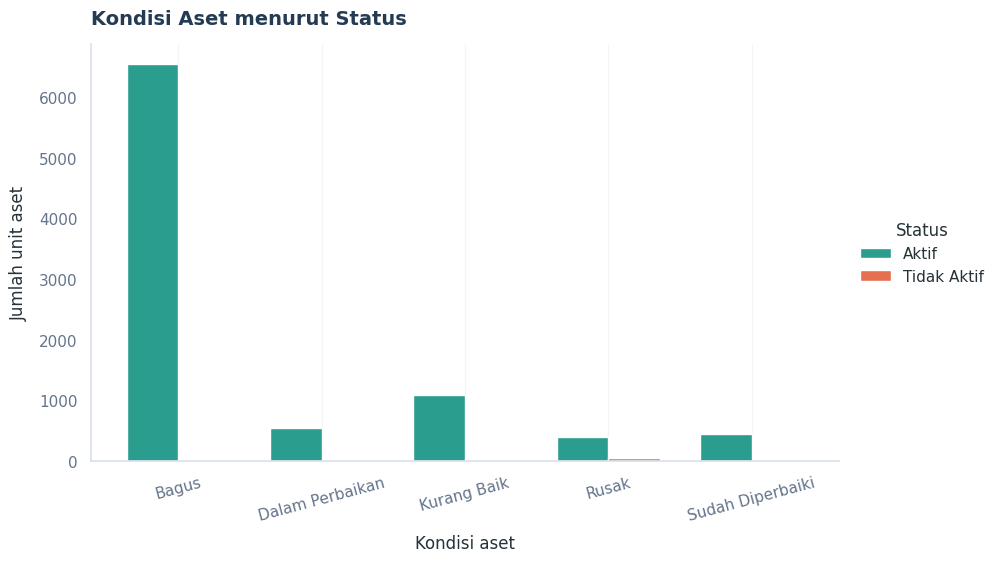

In [60]:
# HUBUNGAN KONDISI DAN STATUS ASET

condition_status = pd.pivot_table(
    df_analysis, index="Kondisi", columns="Status",
    values="Jumlah", aggfunc="sum", fill_value=0,
    margins=True, margins_name="Total"
)
display(condition_status)

condition_status_plot = pd.crosstab(
    df_analysis["Kondisi"], df_analysis["Status"],
    values=df_analysis["Jumlah"], aggfunc="sum"
).fillna(0)

fig, ax = plt.subplots(figsize=(11, 5.8))
condition_status_plot.plot(
    kind="bar", ax=ax,
    color=[COLORS["teal"], COLORS["coral"]],
    width=0.72
)
style_axis(ax, "Kondisi Aset menurut Status", "Kondisi aset", "Jumlah unit aset")
ax.tick_params(axis="x", rotation=15)
ax.legend(
    title="Status", frameon=False,
    loc="center left", bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)
ax.grid(axis="y", visible=False)
fig.subplots_adjust(left=0.10, right=0.78, top=0.90, bottom=0.18)
plt.show()

In [61]:
location_analysis = (
    df_analysis.groupby("Lokasi", dropna=False)
    .agg(
        Total_Aset=("Jumlah", "sum"),
        Aset_Bermasalah=(
            "Jumlah",
            lambda s: s[
                df_analysis.loc[s.index, "Is_Problem"].eq(1)
            ].sum()
        ),
        Aset_Rusak=(
            "Jumlah",
            lambda s: s[
                df_analysis.loc[s.index, "Is_Damaged"].eq(1)
            ].sum()
        )
    )
    .reset_index()
)

location_analysis["Problem Rate (%)"] = (
    location_analysis["Aset_Bermasalah"]
    / location_analysis["Total_Aset"].replace(0, np.nan)
    * 100
).fillna(0)

location_analysis["Rusak Rate (%)"] = (
    location_analysis["Aset_Rusak"]
    / location_analysis["Total_Aset"].replace(0, np.nan)
    * 100
).fillna(0)

location_analysis = location_analysis.sort_values(
    ["Problem Rate (%)", "Aset_Bermasalah"],
    ascending=False
)

display(location_analysis.round(2))

,Lokasi,Total_Aset,Aset_Bermasalah,Aset_Rusak,Problem Rate (%),Rusak Rate (%)
26,IPAM Ngagel III,122,33,9,27.05,7.38
16,Gedung Blok D Lantai I,82,22,6,26.83,7.32
19,Gudang Ratna,432,114,28,26.39,6.48
8,Gedung Blok B Lantai I,490,129,28,26.33,5.71
27,Plintahan,23,6,1,26.09,4.35
23,IPAM Karangpilang IV,104,27,9,25.96,8.65
3,Gedung Blok A Lantai I,273,70,9,25.64,3.30
29,Toyoarang,8,2,2,25.00,25.00
0,Badan Pembina Olahraga,189,47,8,24.87,4.23
6,Gedung Blok A Lantai IV,498,123,24,24.70,4.82


## **Visualisasi Problem Rate Lokasi**
Grafik ini mengurutkan lokasi berdasarkan proporsi aset bermasalah. Problem rate perlu dibaca bersama jumlah aset bermasalah absolut.

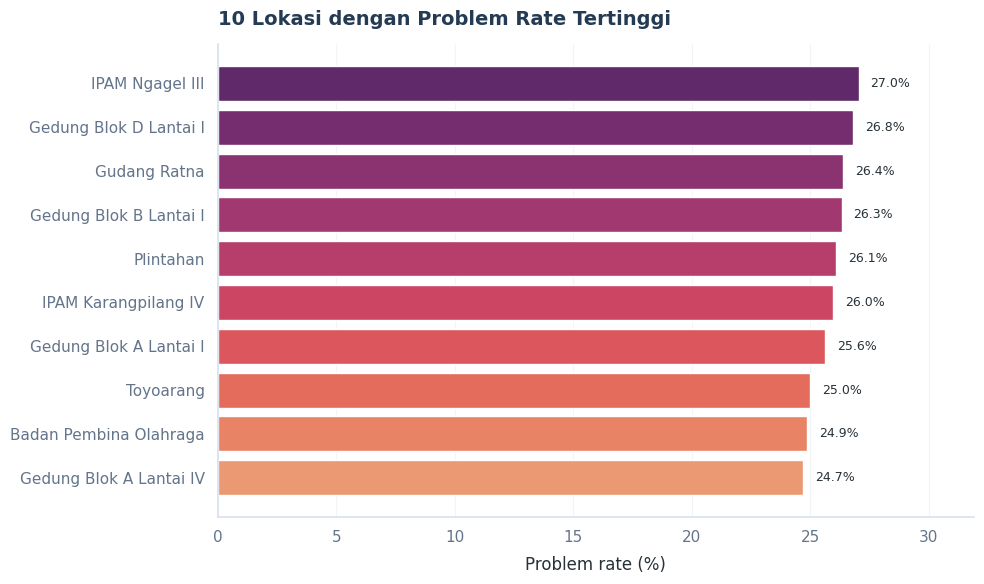

In [62]:
# LOKASI DENGAN PROBLEM RATE TERTINGGI

top_priority = (
    location_analysis.nlargest(10, "Problem Rate (%)")
    .sort_values("Problem Rate (%)", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_priority["Lokasi"], top_priority["Problem Rate (%)"],
               color=sns.color_palette("flare", n_colors=len(top_priority)))
style_axis(ax, "10 Lokasi dengan Problem Rate Tertinggi",
           "Problem rate (%)", None)
for bar in bars:
    ax.text(bar.get_width() + 0.5,
            bar.get_y() + bar.get_height()/2,
            f"{bar.get_width():.1f}%",
            va="center", fontsize=9, color=COLORS["dark"])
ax.set_xlim(0, max(5, top_priority["Problem Rate (%)"].max()*1.18))
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [63]:
def classify_problem_rate(rate):
    if rate >= 30:
        return "Problem Rate Tinggi"
    elif rate >= 15:
        return "Problem Rate Menengah"
    return "Problem Rate Rendah"

location_analysis["Kategori Prioritas"] = (
    location_analysis["Problem Rate (%)"]
    .apply(classify_problem_rate)
)

display(
    location_analysis[
        [
            "Lokasi",
            "Total_Aset",
            "Aset_Bermasalah",
            "Problem Rate (%)",
            "Kategori Prioritas"
        ]
    ].round(2)
)

,Lokasi,Total_Aset,Aset_Bermasalah,Problem Rate (%),Kategori Prioritas
26,IPAM Ngagel III,122,33,27.05,Problem Rate Menengah
16,Gedung Blok D Lantai I,82,22,26.83,Problem Rate Menengah
19,Gudang Ratna,432,114,26.39,Problem Rate Menengah
8,Gedung Blok B Lantai I,490,129,26.33,Problem Rate Menengah
27,Plintahan,23,6,26.09,Problem Rate Menengah
23,IPAM Karangpilang IV,104,27,25.96,Problem Rate Menengah
3,Gedung Blok A Lantai I,273,70,25.64,Problem Rate Menengah
29,Toyoarang,8,2,25.00,Problem Rate Menengah
0,Badan Pembina Olahraga,189,47,24.87,Problem Rate Menengah
6,Gedung Blok A Lantai IV,498,123,24.70,Problem Rate Menengah


In [64]:
rfm_feasibility = pd.DataFrame([
    {
        "Fitur": "Recency",
        "Kebutuhan Data": "Tanggal aktivitas terakhir aset",
        "Status": "Belum tersedia pada dataset utama",
        "Tindak Lanjut": "Memerlukan riwayat pemeliharaan atau mutasi"
    },
    {
        "Fitur": "Frequency",
        "Kebutuhan Data": "Jumlah aktivitas aset dalam periode tertentu",
        "Status": "Belum tersedia pada dataset utama",
        "Tindak Lanjut": "Memerlukan riwayat aktivitas aset"
    },
    {
        "Fitur": "Monetary",
        "Kebutuhan Data": "Nilai perolehan aset",
        "Status": (
            "Belum tersedia"
            if "Nilai Perolehan" not in df_clean.columns
            else "Perlu pemeriksaan kelengkapan dan format"
        ),
        "Tindak Lanjut": "Verifikasi sumber nilai perolehan"
    }
])

display(rfm_feasibility)

,Fitur,Kebutuhan Data,Status,Tindak Lanjut
0,Recency,Tanggal aktivitas terakhir aset,Belum tersedia pada dataset utama,Memerlukan riwayat pemeliharaan atau mutasi
1,Frequency,Jumlah aktivitas aset dalam periode tertentu,Belum tersedia pada dataset utama,Memerlukan riwayat aktivitas aset
2,Monetary,Nilai perolehan aset,Belum tersedia,Verifikasi sumber nilai perolehan


In [65]:
if "Tahun Pembelian" in df_clean.columns:
    total_rows = len(df_clean)
    missing_year = df_clean["Tahun Pembelian"].isna().sum()
    available_year = total_rows - missing_year

    year_completeness = pd.DataFrame({
        "Indikator": [
            "Total baris",
            "Tahun pembelian tersedia",
            "Tahun pembelian kosong",
            "Kelengkapan tahun pembelian (%)",
            "Persentase tahun pembelian kosong (%)"
        ],
        "Nilai": [
            total_rows,
            available_year,
            missing_year,
            calculate_rate(available_year, total_rows),
            calculate_rate(missing_year, total_rows)
        ]
    })

    display(year_completeness.round(2))

    display(
        df_clean["Tahun Pembelian"]
        .dropna()
        .value_counts()
        .sort_index()
        .rename_axis("Tahun Pembelian")
        .reset_index(name="Jumlah Aset")
    )

,Indikator,Nilai
0,Total baris,"9,110.00"
1,Tahun pembelian tersedia,913.00
2,Tahun pembelian kosong,"8,197.00"
3,Kelengkapan tahun pembelian (%),10.02
4,Persentase tahun pembelian kosong (%),89.98


,Tahun Pembelian,Jumlah Aset
0,1982,1
1,1989,3
2,1991,5
3,1992,37
4,1993,3
5,1994,4
6,1995,2
7,1996,3
8,1999,1
9,2002,1


In [66]:
print("RINGKASAN ANALITIK INVENTARIS")
print("=" * 45)

print(f"Total aset: {total_assets:,.0f}")
print(
    f"Aset bermasalah: {problem_assets:,.0f} "
    f"({calculate_rate(problem_assets, total_assets):.2f}%)"
)
print(
    f"Aset rusak: {damaged_assets:,.0f} "
    f"({calculate_rate(damaged_assets, total_assets):.2f}%)"
)
print(
    f"Aset tidak aktif: {inactive_assets:,.0f} "
    f"({calculate_rate(inactive_assets, total_assets):.2f}%)"
)

if not location_analysis.empty:
    highest_rate = location_analysis.iloc[0]

    highest_count = location_analysis.sort_values(
        "Aset_Bermasalah",
        ascending=False
    ).iloc[0]

    print("\nLokasi dengan Problem Rate tertinggi:")
    print(
        f"{highest_rate['Lokasi']} — "
        f"{highest_rate['Problem Rate (%)']:.2f}%"
    )

    print("\nLokasi dengan jumlah aset bermasalah terbanyak:")
    print(
        f"{highest_count['Lokasi']} — "
        f"{highest_count['Aset_Bermasalah']:,.0f} aset"
    )

RINGKASAN ANALITIK INVENTARIS
Total aset: 9,110
Aset bermasalah: 2,094 (22.99%)
Aset rusak: 455 (4.99%)
Aset tidak aktif: 53 (0.58%)

Lokasi dengan Problem Rate tertinggi:
IPAM Ngagel III — 27.05%

Lokasi dengan jumlah aset bermasalah terbanyak:
IPAM Ngagel I — 182 aset


In [67]:
total_rows = len(df_analysis)
total_asset_units = df_analysis["Jumlah"].sum()

problem_count_check = df_analysis.loc[
    df_analysis["Kondisi"].isin(problem_conditions),
    "Jumlah"
].sum()

damaged_count_check = df_analysis.loc[
    df_analysis["Kondisi"].eq("Rusak"),
    "Jumlah"
].sum()

inactive_count_check = df_analysis.loc[
    df_analysis["Status"].eq("Tidak Aktif"),
    "Jumlah"
].sum()

validation_results = pd.DataFrame([
    {
        "Pengujian": "Jumlah baris data",
        "Hasil": total_rows,
        "Kriteria": "Sesuai jumlah baris sumber",
        "Status": "LULUS" if total_rows == len(df_raw) else "PERIKSA"
    },
    {
        "Pengujian": "Total unit aset",
        "Hasil": total_asset_units,
        "Kriteria": "Sama dengan penjumlahan kolom Jumlah",
        "Status": (
            "LULUS"
            if total_asset_units == df_analysis["Jumlah"].sum()
            else "PERIKSA"
        )
    },
    {
        "Pengujian": "Aset bermasalah",
        "Hasil": problem_count_check,
        "Kriteria": "Sama dengan jumlah tiga kondisi bermasalah",
        "Status": (
            "LULUS"
            if problem_count_check == problem_assets
            else "PERIKSA"
        )
    },
    {
        "Pengujian": "Aset rusak",
        "Hasil": damaged_count_check,
        "Kriteria": "Sama dengan jumlah kondisi Rusak",
        "Status": (
            "LULUS"
            if damaged_count_check == damaged_assets
            else "PERIKSA"
        )
    },
    {
        "Pengujian": "Aset tidak aktif",
        "Hasil": inactive_count_check,
        "Kriteria": "Sama dengan jumlah status Tidak Aktif",
        "Status": (
            "LULUS"
            if inactive_count_check == inactive_assets
            else "PERIKSA"
        )
    }
])

display(validation_results)

,Pengujian,Hasil,Kriteria,Status
0,Jumlah baris data,9110,Sesuai jumlah baris sumber,LULUS
1,Total unit aset,9110,Sama dengan penjumlahan kolom Jumlah,LULUS
2,Aset bermasalah,2094,Sama dengan jumlah tiga kondisi bermasalah,LULUS
3,Aset rusak,455,Sama dengan jumlah kondisi Rusak,LULUS
4,Aset tidak aktif,53,Sama dengan jumlah status Tidak Aktif,LULUS


In [68]:
condition_total = df_analysis.groupby(
    "Kondisi", dropna=False
)["Jumlah"].sum().sum()

status_total = df_analysis.groupby(
    "Status", dropna=False
)["Jumlah"].sum().sum()

consistency_check = pd.DataFrame({
    "Pemeriksaan": [
        "Total aset dari data utama",
        "Total hasil rekap kondisi",
        "Total hasil rekap status"
    ],
    "Nilai": [
        total_asset_units,
        condition_total,
        status_total
    ]
})

consistency_check["Selisih dari Total Utama"] = (
    consistency_check["Nilai"] - total_asset_units
)

display(consistency_check)

assert condition_total == total_asset_units, (
    "Total rekap kondisi tidak sesuai dengan total utama."
)

assert status_total == total_asset_units, (
    "Total rekap status tidak sesuai dengan total utama."
)

print("Validasi konsistensi agregasi selesai.")

,Pemeriksaan,Nilai,Selisih dari Total Utama
0,Total aset dari data utama,9110,0
1,Total hasil rekap kondisi,9110,0
2,Total hasil rekap status,9110,0


Validasi konsistensi agregasi selesai.


In [69]:
output_file = "Hasil_Analisis_Awal_Inventaris_PDAM.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df_clean.to_excel(
        writer,
        sheet_name="Data_Clean",
        index=False
    )

    data_dictionary.to_excel(
        writer,
        sheet_name="Data_Dictionary",
        index=False
    )

    kpi_summary.to_excel(
        writer,
        sheet_name="KPI_Inventaris",
        index=False
    )

    location_analysis.to_excel(
        writer,
        sheet_name="Prioritas_Lokasi",
        index=False
    )

    condition_status.to_excel(
        writer,
        sheet_name="Kondisi_Status"
    )

    validation_results.to_excel(
        writer,
        sheet_name="Evaluasi",
        index=False
    )

    rfm_feasibility.to_excel(
        writer,
        sheet_name="Kelayakan_RFM",
        index=False
    )

    dataset_information.to_excel(
        writer,
        sheet_name="Informasi_Dataset",
        index=False
    )

files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6.1 Persiapan Variabel Analisis

Tahap ini memastikan kolom penting tersedia, nilai teks konsisten, dan jumlah aset dapat diagregasikan. Definisi aset bermasalah pada analisis awal menggunakan kondisi *Kurang Baik*, *Dalam Perbaikan*, dan *Rusak*. Definisi ini perlu dikonfirmasi kepada pengelola inventaris sebelum dipakai sebagai indikator operasional resmi.

Aset dengan kondisi *Sudah Diperbaiki* tidak dimasukkan ke kategori bermasalah pada definisi awal. Klasifikasi ini tidak menyatakan bahwa aset tersebut tidak membutuhkan pemantauan lanjutan.

In [70]:
# PERSIAPAN DATA ANALISIS LANJUTAN

required_columns = [
    "Lokasi", "Bagian", "Kategori", "Nama Barang",
    "Jumlah", "Kondisi", "Status"
]
missing_required = [c for c in required_columns if c not in df_clean.columns]

if missing_required:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_required}")

df_bi = df_clean.copy()

# Pastikan kolom jumlah numerik dan nilai tidak valid tidak ikut dijumlahkan
df_bi["Jumlah"] = pd.to_numeric(df_bi["Jumlah"], errors="coerce").fillna(0)

# Normalisasi kategori kosong agar dapat ditampilkan sebagai kelompok tersendiri
for col in ["Lokasi", "Bagian", "Kategori", "Nama Barang", "Kondisi", "Status"]:
    df_bi[col] = (
        df_bi[col].astype("string").str.strip()
        .replace({"": pd.NA, "-": pd.NA})
        .fillna("Tidak Diketahui")
    )

problem_conditions = ["Kurang Baik", "Dalam Perbaikan", "Rusak"]
df_bi["Aset_Bermasalah"] = np.where(
    df_bi["Kondisi"].isin(problem_conditions), df_bi["Jumlah"], 0
)
df_bi["Aset_Rusak"] = np.where(
    df_bi["Kondisi"].eq("Rusak"), df_bi["Jumlah"], 0
)

print("Jumlah baris analisis:", len(df_bi))
print("Total unit aset:", f"{df_bi['Jumlah'].sum():,.0f}")
print("Jumlah lokasi:", df_bi["Lokasi"].nunique())
print("Jumlah bagian:", df_bi["Bagian"].nunique())

Jumlah baris analisis: 9110
Total unit aset: 9,110
Jumlah lokasi: 31
Jumlah bagian: 51


## 6.2 Comparative Analysis: Perbandingan Antarbagian

Analisis ini memperluas analisis lokasi yang telah dilakukan sebelumnya. Perbandingan dilakukan pada seluruh bagian yang tercatat, menggunakan jumlah aset, jumlah aset bermasalah, dan *problem rate*.

*Problem rate* dihitung sebagai jumlah unit aset bermasalah dibagi total unit aset pada kelompok yang sama. Nilai ini perlu dibaca bersama jumlah aset bermasalah absolut agar kelompok dengan jumlah aset sangat kecil tidak langsung dianggap paling prioritas.

## **Visualisasi Perbandingan Antarbagian**
Grafik menampilkan bagian dengan jumlah aset bermasalah terbesar untuk membantu menentukan area yang perlu ditinjau lebih lanjut.

,Bagian,Total_Aset,Aset_Bermasalah,Aset_Rusak,Jumlah_Lokasi,Problem Rate (%),Rusak Rate (%)
10,Kinerja dan Standardisasi,11,5,1,1,45.45,9.09
48,Subdit Sekretaris Perusahaan,72,24,5,3,33.33,6.94
2,Direktorat Keuangan,43,14,2,1,32.56,4.65
38,Subdit Kelola Sistem Informasi dan Aset Properti,10,3,0,1,30.00,0.00
35,Sistem dan Pengembangan Sumber Daya Manusia,44,13,3,1,29.55,6.82
30,Proyek Produksi dan Distribusi,46,13,1,1,28.26,2.17
18,Penertiban,94,26,7,1,27.66,7.45
4,Direktorat Pelayanan,29,8,1,1,27.59,3.45
1,Anggaran dan Kas,110,30,5,1,27.27,4.55
3,Direktorat Operasi,44,12,1,1,27.27,2.27


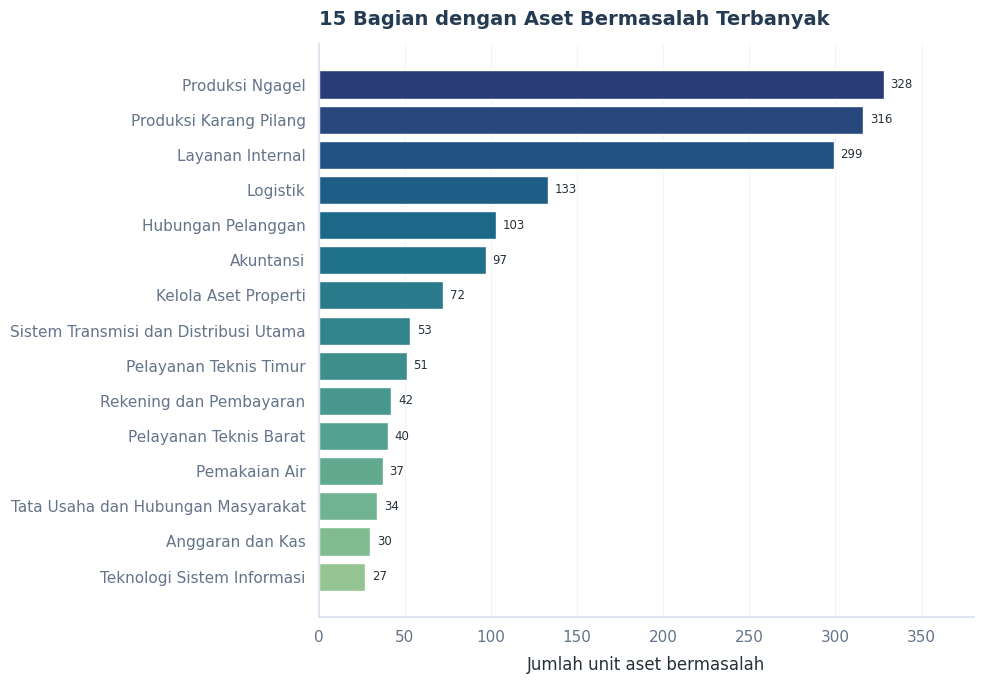

In [71]:
# PERBANDINGAN ASET BERMASALAH ANTARBAGIAN

part_analysis = (
    df_bi.groupby("Bagian", dropna=False)
    .agg(
        Total_Aset=("Jumlah", "sum"),
        Aset_Bermasalah=("Aset_Bermasalah", "sum"),
        Aset_Rusak=("Aset_Rusak", "sum"),
        Jumlah_Lokasi=("Lokasi", "nunique")
    ).reset_index()
)

part_analysis["Problem Rate (%)"] = (
    part_analysis["Aset_Bermasalah"]
    .div(part_analysis["Total_Aset"].replace(0, np.nan)).mul(100)
)
part_analysis["Rusak Rate (%)"] = (
    part_analysis["Aset_Rusak"]
    .div(part_analysis["Total_Aset"].replace(0, np.nan)).mul(100)
)

part_analysis = part_analysis.sort_values(
    ["Problem Rate (%)", "Aset_Bermasalah"], ascending=[False, False]
)
display(part_analysis.round(2))

top_parts_problem = part_analysis.nlargest(15, "Aset_Bermasalah").sort_values(
    "Aset_Bermasalah", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top_parts_problem["Bagian"], top_parts_problem["Aset_Bermasalah"],
               color=sns.color_palette("crest", n_colors=len(top_parts_problem)))
style_axis(ax, "15 Bagian dengan Aset Bermasalah Terbanyak",
           "Jumlah unit aset bermasalah", None)
for bar in bars:
    ax.text(bar.get_width() + top_parts_problem["Aset_Bermasalah"].max()*0.012,
            bar.get_y() + bar.get_height()/2, f"{bar.get_width():,.0f}",
            va="center", fontsize=8.5, color=COLORS["dark"])
ax.set_xlim(0, top_parts_problem["Aset_Bermasalah"].max()*1.16)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6.3 Comparative Analysis: Kondisi berdasarkan Kategori dan Lokasi

Analisis ini digunakan untuk melihat apakah komposisi kondisi berbeda pada kategori barang atau lokasi yang berbeda. Hasilnya menjadi dasar filter dan grafik komparatif pada dashboard.

## **Visualisasi Kondisi menurut Kategori**
Grafik bertumpuk 100% membandingkan proporsi kondisi pada setiap kategori sehingga komposisi dapat dibandingkan secara proporsional.

Kategori,Elektronik,Mebelair,Total
Kondisi,,,
Bagus,1137,5422,6559
Dalam Perbaikan,82,464,546
Kurang Baik,192,901,1093
Rusak,72,383,455
Sudah Diperbaiki,65,392,457
Total,1548,7562,9110


Kondisi,Bagus,Dalam Perbaikan,Kurang Baik,Rusak,Sudah Diperbaiki
Kategori,,,,,
Elektronik,73.45,5.30,12.40,4.65,4.20
Mebelair,71.70,6.14,11.91,5.06,5.18


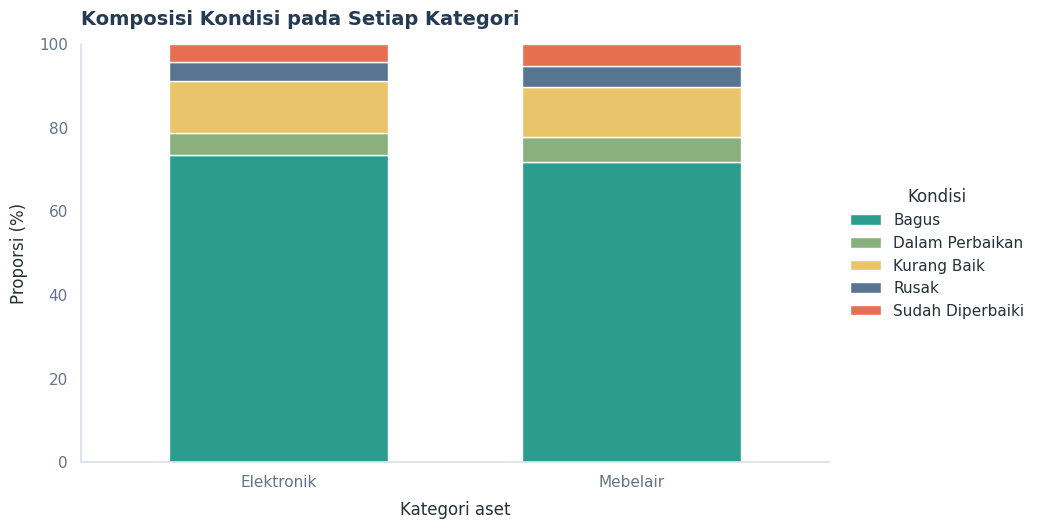

In [72]:
# PERBANDINGAN KONDISI ASET BERDASARKAN KATEGORI

condition_category = pd.pivot_table(
    df_bi, index="Kondisi", columns="Kategori",
    values="Jumlah", aggfunc="sum", fill_value=0,
    margins=True, margins_name="Total"
)
display(condition_category)

condition_category_pct = pd.crosstab(
    df_bi["Kategori"], df_bi["Kondisi"],
    values=df_bi["Jumlah"], aggfunc="sum"
).fillna(0)

condition_category_pct = condition_category_pct.div(
    condition_category_pct.sum(axis=1).replace(0, np.nan), axis=0
).mul(100)
display(condition_category_pct.round(2))

fig, ax = plt.subplots(figsize=(11, 5.8))
condition_category_pct.plot(
    kind="bar", stacked=True, figsize=(11, 5.8),
    color=[COLORS["teal"], COLORS["sage"], COLORS["amber"],
           COLORS["blue"], COLORS["coral"]], ax=ax, width=0.62
)
style_axis(ax, "Komposisi Kondisi pada Setiap Kategori",
           "Kategori aset", "Proporsi (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(
    title="Kondisi", bbox_to_anchor=(1.02, 0.5),
    loc="center left", frameon=False, borderaxespad=0
)
ax.grid(axis="y", visible=False)
fig.subplots_adjust(left=0.10, right=0.78, top=0.90, bottom=0.18)
plt.show()

## 6.4 Pareto Analysis: Kontribusi Aset Bermasalah

Pareto analysis digunakan untuk mengurutkan kelompok penyumbang aset bermasalah dari kontribusi terbesar hingga terkecil, kemudian menghitung persentase kumulatifnya. Analisis dapat dilakukan berdasarkan lokasi, bagian, dan nama barang.

Garis 80% pada diagram Pareto merupakan panduan visual untuk membaca konsentrasi kontribusi, bukan batas otomatis yang menyatakan kelompok di atas garis harus ditangani tanpa pertimbangan lain.

## **Visualisasi Pareto**
Batang menunjukkan jumlah aset bermasalah, sedangkan garis menunjukkan kontribusi kumulatif. Garis 80% menjadi panduan membaca konsentrasi kontribusi.

,Lokasi,Aset_Bermasalah,Kontribusi (%),Kumulatif (%)
0,IPAM Ngagel I,182,8.69,8.69
1,Gedung Blok A Lantai II,158,7.55,16.24
2,Gedung Blok A Lantai III,133,6.35,22.59
3,Gedung Blok B Lantai I,129,6.16,28.75
4,Gedung Blok A Lantai IV,123,5.87,34.62
5,IPAM Karangpilang I,118,5.64,40.26
6,Gudang Ratna,114,5.44,45.70
7,IPAM Ngagel II,113,5.40,51.10
8,IPAM Karangpilang II,105,5.01,56.11
9,Gedung Blok B Lantai II,90,4.30,60.41


,Bagian,Aset_Bermasalah,Kontribusi (%),Kumulatif (%)
0,Produksi Ngagel,328,15.66,15.66
1,Produksi Karang Pilang,316,15.09,30.75
2,Layanan Internal,299,14.28,45.03
3,Logistik,133,6.35,51.38
4,Hubungan Pelanggan,103,4.92,56.30
5,Akuntansi,97,4.63,60.94
6,Kelola Aset Properti,72,3.44,64.37
7,Sistem Transmisi dan Distribusi Utama,53,2.53,66.91
8,Pelayanan Teknis Timur,51,2.44,69.34
9,Rekening dan Pembayaran,42,2.01,71.35


,Nama Barang,Aset_Bermasalah,Kontribusi (%),Kumulatif (%)
0,Kursi,601,28.70,28.70
1,Meja,453,21.63,50.33
2,Lemari,218,10.41,60.74
3,Filling Cabinet,157,7.50,68.24
4,Rak,133,6.35,74.59
5,AC,124,5.92,80.52
6,Mesin,63,3.01,83.52
7,Telepon,49,2.34,85.86
8,Loker,47,2.24,88.11
9,Sofa,38,1.81,89.92


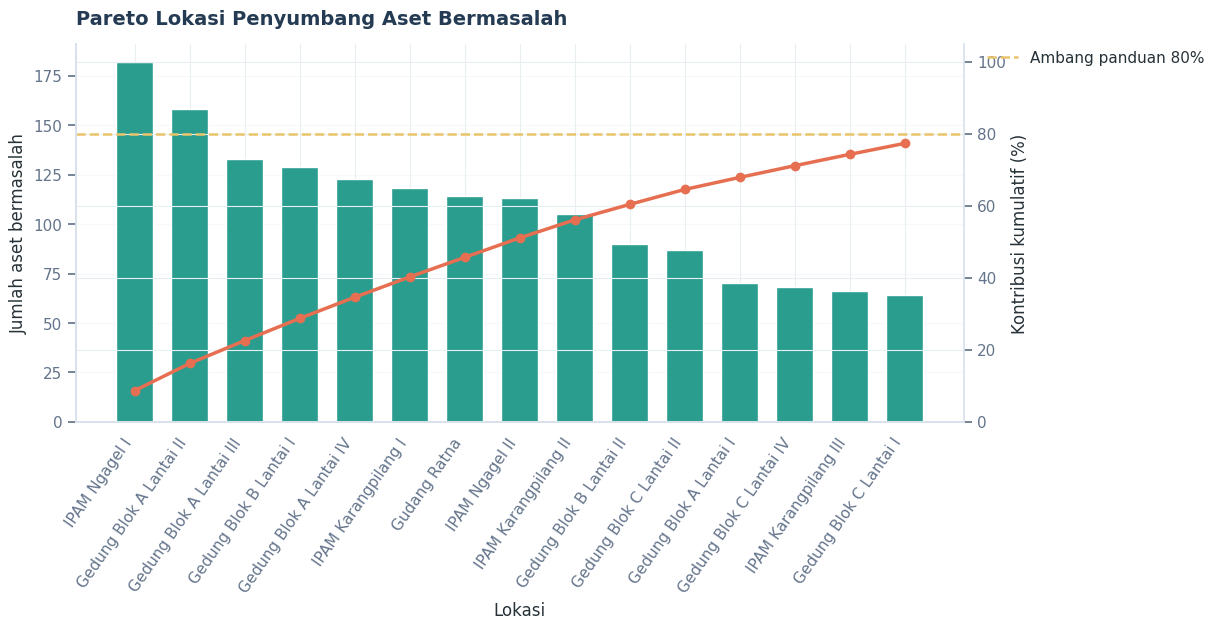

In [73]:
# PARETO ANALYSIS ASET BERMASALAH

def create_pareto(data, group_col, value_col="Aset_Bermasalah"):
    result = (
        data.groupby(group_col, dropna=False)[value_col]
        .sum().sort_values(ascending=False).reset_index()
    )
    result = result[result[value_col] > 0].copy()
    total = result[value_col].sum()
    if total > 0:
        result["Kontribusi (%)"] = result[value_col] / total * 100
        result["Kumulatif (%)"] = result["Kontribusi (%)"].cumsum()
    else:
        result["Kontribusi (%)"] = 0.0
        result["Kumulatif (%)"] = 0.0
    return result

pareto_location = create_pareto(df_bi, "Lokasi")
pareto_part = create_pareto(df_bi, "Bagian")
pareto_item = create_pareto(df_bi, "Nama Barang")

display(pareto_location.head(15).round(2))
display(pareto_part.head(15).round(2))
display(pareto_item.head(15).round(2))

pareto_plot = pareto_location.head(15).copy()
fig, ax1 = plt.subplots(figsize=(12, 6))
x = np.arange(len(pareto_plot))
ax1.bar(x, pareto_plot["Aset_Bermasalah"], color=COLORS["teal"], width=0.68)
ax1.set_ylabel("Jumlah aset bermasalah")
ax1.set_xlabel("Lokasi")
ax1.set_xticks(x)
ax1.set_xticklabels(pareto_plot["Lokasi"], rotation=55, ha="right")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="y", alpha=0.35)
ax1.set_axisbelow(True)

ax2 = ax1.twinx()
ax2.plot(x, pareto_plot["Kumulatif (%)"], color=COLORS["coral"],
         marker="o", linewidth=2.5, markersize=6)
ax2.axhline(80, color=COLORS["amber"], linestyle="--", linewidth=1.8,
            label="Ambang panduan 80%")
ax2.set_ylabel("Kontribusi kumulatif (%)")
ax2.set_ylim(0, 105)
ax2.spines["top"].set_visible(False)
ax2.legend(
    frameon=False, loc="upper left",
    bbox_to_anchor=(1.02, 1.0), borderaxespad=0
)

ax1.set_title("Pareto Lokasi Penyumbang Aset Bermasalah",
              loc="left", pad=14, color=COLORS["navy"], fontweight="bold")
fig.subplots_adjust(left=0.08, right=0.82, top=0.88, bottom=0.25)
plt.show()

## 7. Analisis Kualitas Data untuk Mendukung Keputusan

Kualitas informasi inventaris memengaruhi ketepatan analisis. Bagian ini menghitung kelengkapan atribut penting, termasuk tahun pembelian, spesifikasi, merek, bahan, PIC, dan kode aset.

Nilai kosong tidak diisi dengan perkiraan. Hasilnya ditampilkan sebagai informasi yang dapat membantu pengelola menentukan prioritas pembaruan data.

## **Visualisasi Kualitas Data**
Grafik menunjukkan persentase kelengkapan tiap atribut. Warna coral menandai kelengkapan rendah, amber menengah, dan teal tinggi.

,Variabel,Jumlah Kosong,Kelengkapan (%),Kekosongan (%)
10,Tahun Pembelian,8197,10.02,89.98
9,Bahan,1983,78.23,21.77
6,Merk,124,98.64,1.36
7,Ukuran / Spesifikasi,92,98.99,1.01
8,Warna,2,99.98,0.02
3,Kategori,0,100.00,0.00
0,Kode Asset,0,100.00,0.00
1,Lokasi,0,100.00,0.00
4,Nama Barang,0,100.00,0.00
5,Fungsi / Tipe,0,100.00,0.00


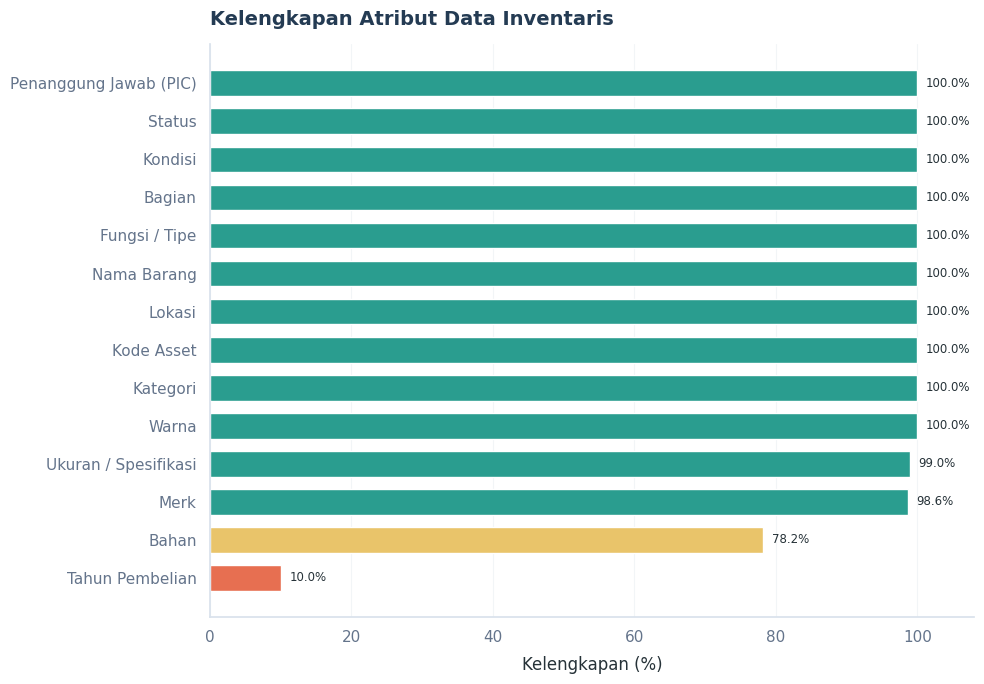

In [74]:
# ANALISIS KELENGKAPAN ATRIBUT DATA INVENTARIS

quality_columns = [
    c for c in [
        "Kode Asset", "Lokasi", "Bagian", "Kategori", "Nama Barang",
        "Fungsi / Tipe", "Merk", "Ukuran / Spesifikasi", "Warna",
        "Bahan", "Tahun Pembelian", "Kondisi", "Status",
        "Penanggung Jawab (PIC)"
    ] if c in df_raw.columns
]

quality_rows = []
for col in quality_columns:
    values = df_raw[col].astype("string").str.strip()
    missing_mask = values.isna() | values.isin(["", "-"])
    quality_rows.append({
        "Variabel": col,
        "Jumlah Kosong": int(missing_mask.sum()),
        "Kelengkapan (%)": round((~missing_mask).mean() * 100, 2),
        "Kekosongan (%)": round(missing_mask.mean() * 100, 2)
    })

data_quality = pd.DataFrame(quality_rows).sort_values(
    "Kelengkapan (%)", ascending=True
)
display(data_quality)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    data_quality["Variabel"], data_quality["Kelengkapan (%)"],
    color=[COLORS["coral"] if v < 50 else COLORS["amber"] if v < 85
           else COLORS["teal"] for v in data_quality["Kelengkapan (%)"]],
    height=0.68
)
style_axis(ax, "Kelengkapan Atribut Data Inventaris",
           "Kelengkapan (%)", None)
ax.set_xlim(0, 108)
for bar in bars:
    ax.text(bar.get_width() + 1.2,
            bar.get_y() + bar.get_height()/2,
            f"{bar.get_width():.1f}%",
            va="center", fontsize=8.5, color=COLORS["dark"])
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 8. Business Process Analysis dan Multiple Business Perspectives

RPS mencakup *Process Analysis* dan *Analysis of Multiple Business Perspectives*. Dataset saat ini merupakan data inventaris berbentuk snapshot, bukan log transaksi berurutan. Karena itu, notebook belum dapat melakukan process mining atau menghitung durasi proses aktual.

Sebagai analisis awal, proses pengelolaan aset dapat dipetakan secara konseptual untuk mengidentifikasi titik data yang perlu tersedia. Alur berikut perlu divalidasi dengan prosedur resmi PDAM.

**Alur konseptual pengelolaan aset:** pencatatan/pendataan → penempatan pada bagian dan lokasi → pemantauan kondisi dan status → pengajuan tindak lanjut (misalnya perbaikan atau mutasi) → pembaruan data aset.

**Perspektif pengguna informasi:**
- Bagian pengguna aset: membutuhkan daftar aset berdasarkan bagian, lokasi, dan PIC.
- Pengelola inventaris: membutuhkan ringkasan kondisi, status, dan kelengkapan data.
- Manajemen: membutuhkan indikator agregat dan kelompok yang memerlukan perhatian.
- Tim pemeliharaan: membutuhkan daftar aset rusak atau dalam perbaikan untuk ditindaklanjuti.

Analisis perspektif ini diterjemahkan ke dalam filter dan halaman dashboard. Validasi kebutuhan pengguna tetap diperlukan sebelum dashboard digunakan secara operasional.

## 9. Kelayakan Analisis Deret Waktu, Prediksi, dan A/B Testing

RPS mencantumkan deskripsi data, visualisasi, analisis dan prediksi deret waktu, serta A/B testing. Kesesuaian metode harus mengikuti struktur data dan tujuan studi kasus.

| Materi RPS | Kelayakan pada dataset inventaris saat ini | Alasan |
|---|---|---|
| Deskripsi dan visualisasi data | Dapat diterapkan | Dataset memiliki jumlah, kategori, kondisi, status, lokasi, dan bagian |
| Analisis/prediksi deret waktu | Belum memadai | Data saat ini berupa snapshot; tahun pembelian banyak kosong dan bukan catatan berkala kondisi aset |
| A/B Testing | Tidak diterapkan pada analisis aset saat ini | Tidak tersedia dua varian perlakuan/kelompok eksperimen dan metrik hasil eksperimen |
| Process Analysis | Terbatas pada pemetaan konseptual | Belum tersedia event log dengan timestamp aktivitas proses |
| Multiple Business Perspectives | Dapat diterapkan secara analitis | Dataset menyediakan dimensi lokasi, bagian, kategori, kondisi, status, dan PIC |

Jika kelak tersedia riwayat mutasi/perbaikan dengan tanggal aktivitas, analisis proses dapat dikembangkan menjadi process mining. Jika tersedia data kondisi aset berkala, analisis tren atau forecasting dapat dipertimbangkan. A/B testing lebih tepat untuk menguji dua rancangan antarmuka atau prosedur kerja dengan metrik dan rancangan eksperimen yang jelas, bukan dipaksakan pada data inventaris snapshot.

## 10. Penyediaan Data untuk Dashboard

Untuk kebutuhan dashboard, data dibersihkan terlebih dahulu kemudian disediakan sebagai tabel analitik. Pada tahap awal, satu tabel bersih dapat digunakan sebagai sumber dashboard. Jika sistem berkembang, model dimensional dapat dirancang dengan tabel fakta inventaris dan dimensi lokasi, bagian, kategori, kondisi, status, serta waktu pencatatan.

| Komponen model konseptual | Isi |
|---|---|
| Fact_Inventory | Jumlah aset pada setiap catatan inventaris |
| Dim_Location | Lokasi |
| Dim_Department | Bagian |
| Dim_Category | Kategori dan nama barang |
| Dim_Condition | Kondisi aset |
| Dim_Status | Status aset |
| Dim_Date | Tanggal/tahun pencatatan jika tersedia dan valid |

Model ini merupakan rancangan konseptual. Implementasi star schema penuh membutuhkan kunci dan granularitas data yang disepakati dengan pengelola sumber data.

In [75]:
# MENYIAPKAN TABEL RINGKAS UNTUK DASHBOARD

dashboard_kpi = pd.DataFrame({
    "Indikator": [
        "Total unit aset",
        "Total aset bermasalah",
        "Problem rate (%)",
        "Total aset rusak",
        "Aset tidak aktif"
    ],
    "Nilai": [
        df_bi["Jumlah"].sum(),
        df_bi["Aset_Bermasalah"].sum(),
        (
            df_bi["Aset_Bermasalah"].sum()
            / df_bi["Jumlah"].sum() * 100
            if df_bi["Jumlah"].sum() else 0
        ),
        df_bi["Aset_Rusak"].sum(),
        df_bi.loc[df_bi["Status"].eq("Tidak Aktif"), "Jumlah"].sum()
    ]
})

dashboard_location = (
    df_bi.groupby("Lokasi", as_index=False)
    .agg(
        Total_Aset=("Jumlah", "sum"),
        Aset_Bermasalah=("Aset_Bermasalah", "sum"),
        Aset_Rusak=("Aset_Rusak", "sum")
    )
)
dashboard_location["Problem Rate (%)"] = (
    dashboard_location["Aset_Bermasalah"]
    / dashboard_location["Total_Aset"].replace(0, np.nan) * 100
)

dashboard_part = (
    df_bi.groupby("Bagian", as_index=False)
    .agg(
        Total_Aset=("Jumlah", "sum"),
        Aset_Bermasalah=("Aset_Bermasalah", "sum")
    )
)
dashboard_part["Problem Rate (%)"] = (
    dashboard_part["Aset_Bermasalah"]
    / dashboard_part["Total_Aset"].replace(0, np.nan) * 100
)

print("KPI dashboard:")
display(dashboard_kpi.round(2))
print("Ringkasan lokasi:")
display(dashboard_location.head())
print("Ringkasan bagian:")
display(dashboard_part.head())

KPI dashboard:


,Indikator,Nilai
0,Total unit aset,"9,110.00"
1,Total aset bermasalah,"2,094.00"
2,Problem rate (%),22.99
3,Total aset rusak,455.00
4,Aset tidak aktif,53.00


Ringkasan lokasi:


,Lokasi,Total_Aset,Aset_Bermasalah,Aset_Rusak,Problem Rate (%)
0,Badan Pembina Olahraga,189,47,8,24.87
1,Basrah,192,43,5,22.40
2,Duren Sewu,10,2,0,20.00
3,Gedung Blok A Lantai I,273,70,9,25.64
4,Gedung Blok A Lantai II,753,158,28,20.98


Ringkasan bagian:


,Bagian,Total_Aset,Aset_Bermasalah,Problem Rate (%)
0,Akuntansi,417,97,23.26
1,Anggaran dan Kas,110,30,27.27
2,Direktorat Keuangan,43,14,32.56
3,Direktorat Operasi,44,12,27.27
4,Direktorat Pelayanan,29,8,27.59


## 11. Interpretasi dan Rekomendasi Berbasis Data

Bagian ini menghasilkan ringkasan otomatis dari agregasi data. Hasil otomatis tetap perlu dibaca bersama tabel/grafik dan dikonfirmasi dengan pemilik proses. Angka tidak boleh langsung dianggap sebagai keputusan pemeliharaan karena dataset tidak memuat tingkat urgensi operasional, biaya perbaikan, usia teknis, atau tingkat kritikalitas aset.

In [76]:
# RINGKASAN INSIGHT UNTUK BAHAN DASHBOARD

total_units = df_bi["Jumlah"].sum()
problem_units = df_bi["Aset_Bermasalah"].sum()
problem_rate_all = problem_units / total_units * 100 if total_units else 0

print("RINGKASAN INSIGHT INVENTARIS")
print("=" * 55)
print(f"Total unit aset: {total_units:,.0f}")
print(f"Aset bermasalah: {problem_units:,.0f} ({problem_rate_all:.2f}%)")

if not pareto_location.empty:
    top_loc = pareto_location.iloc[0]
    print(
        f"Kontributor aset bermasalah terbesar berdasarkan lokasi: "
        f"{top_loc['Lokasi']} ({top_loc['Aset_Bermasalah']:,.0f} unit; "
        f"{top_loc['Kontribusi (%)']:.2f}% dari aset bermasalah)."
    )

if not pareto_part.empty:
    top_part = pareto_part.iloc[0]
    print(
        f"Kontributor aset bermasalah terbesar berdasarkan bagian: "
        f"{top_part['Bagian']} ({top_part['Aset_Bermasalah']:,.0f} unit; "
        f"{top_part['Kontribusi (%)']:.2f}%)."
    )

if not data_quality.empty:
    lowest_quality = data_quality.iloc[0]
    print(
        f"Atribut dengan kelengkapan terendah: {lowest_quality['Variabel']} "
        f"({lowest_quality['Kelengkapan (%)']:.2f}%)."
    )

print("\nCatatan interpretasi:")
print("- Jumlah terbesar dan problem rate tertinggi adalah dua ukuran berbeda.")
print("- Hasil ini menunjukkan area evaluasi, bukan keputusan pemeliharaan otomatis.")
print("- Rekomendasi operasional perlu divalidasi oleh pengelola aset.")

RINGKASAN INSIGHT INVENTARIS
Total unit aset: 9,110
Aset bermasalah: 2,094 (22.99%)
Kontributor aset bermasalah terbesar berdasarkan lokasi: IPAM Ngagel I (182 unit; 8.69% dari aset bermasalah).
Kontributor aset bermasalah terbesar berdasarkan bagian: Produksi Ngagel (328 unit; 15.66%).
Atribut dengan kelengkapan terendah: Tahun Pembelian (10.02%).

Catatan interpretasi:
- Jumlah terbesar dan problem rate tertinggi adalah dua ukuran berbeda.
- Hasil ini menunjukkan area evaluasi, bukan keputusan pemeliharaan otomatis.
- Rekomendasi operasional perlu divalidasi oleh pengelola aset.


## 12. Evaluasi dan Pengujian Dashboard

Sebelum deployment, dashboard perlu diuji sekurang-kurangnya pada aspek berikut:

1. **Validitas angka:** total KPI dan agregasi pada dashboard harus sama dengan hasil notebook.
2. **Konsistensi filter:** filter lokasi, bagian, kategori, kondisi, dan status harus mengubah seluruh komponen visual secara konsisten.
3. **Keterbacaan visual:** judul, satuan, label, legenda, dan sumber data harus jelas.
4. **Kegunaan informasi:** pengguna dapat menemukan aset atau kelompok aset yang ingin dievaluasi.
5. **Keamanan:** data internal hanya ditampilkan sesuai izin PDAM; deployment tidak boleh membuka informasi sensitif kepada publik.

A/B testing tidak otomatis diperlukan untuk menguji dashboard ini. Pengujian fungsional dan evaluasi pengguna lebih sesuai untuk tahap implementasi awal. A/B testing baru dapat dilakukan jika tersedia dua versi antarmuka/prosedur, pembagian pengguna yang tepat, dan metrik evaluasi yang ditentukan sebelumnya.

## 13. Kesimpulan Pengembangan

Notebook awal telah menyediakan fondasi berupa data understanding, data cleaning, EDA, deskripsi kondisi/status, KPI inventaris, tabulasi silang kondisi-status, analisis lokasi, dan validasi agregasi. Pengembangan ini menambahkan analisis per bagian, perbandingan kondisi berdasarkan kategori, Pareto analysis, analisis kualitas data, perspektif pengguna bisnis, rancangan penyediaan data, serta ringkasan insight.

Dengan pengembangan tersebut, hasil notebook dapat menjadi dasar dashboard Streamlit yang berfokus pada transformasi data inventaris menjadi informasi dan insight untuk pemantauan serta evaluasi aset seluruh bagian yang tercatat.

**Batasan:** dataset yang digunakan adalah snapshot inventaris. Analisis tren waktu, forecasting, process mining, dan A/B testing tidak diklaim telah dilakukan karena kebutuhan data/metodologinya belum tersedia. Seluruh definisi indikator, terutama kategori aset bermasalah, perlu dikonfirmasi dengan pengelola PDAM.

## 14. Data Mining: Pemilihan Pendekatan yang Sesuai

Dalam konteks proyek ini, data mining dipahami sebagai proses menemukan pola atau informasi yang berguna dari data. Analisis yang telah diterapkan, seperti pengelompokan agregat, perbandingan, dan Pareto, merupakan analisis eksploratif/deskriptif untuk menemukan pola distribusi dan konsentrasi aset bermasalah.

Algoritma machine learning seperti K-Means tidak dipaksakan sebagai metode utama karena tujuan proyek saat ini adalah pemantauan dan evaluasi inventaris, sedangkan sebagian besar atribut bersifat kategorikal. Penggunaan algoritma clustering memerlukan perumusan tujuan segmentasi, pemilihan representasi fitur yang tepat, serta evaluasi hasil yang dapat dipertanggungjawabkan.

Predictive analytics juga belum diterapkan. Dataset saat ini berupa snapshot dan belum menyediakan riwayat kondisi atau aktivitas aset berkala yang memadai untuk membangun model prediksi. Jika PDAM menyediakan data historis perbaikan, mutasi, atau perubahan kondisi, analisis prediktif dapat menjadi pengembangan berikutnya.

## 15. Model Multidimensional dan Perspektif Pelaporan

Dashboard dirancang agar informasi dapat dilihat dari beberapa perspektif bisnis (*multiple business perspectives*). Dimensi analisis yang digunakan adalah:

| Perspektif | Contoh pertanyaan bisnis |
|---|---|
| Lokasi | Lokasi mana yang memiliki jumlah aset atau aset bermasalah terbanyak? |
| Bagian | Bagaimana distribusi dan kondisi aset pada setiap bagian? |
| Kategori/nama barang | Jenis barang apa yang paling banyak dan bagaimana kondisi masing-masing? |
| Kondisi | Berapa jumlah aset bagus, kurang baik, dalam perbaikan, sudah diperbaiki, dan rusak? |
| Status | Bagaimana perbandingan aset aktif dan tidak aktif? |

Pengguna dapat melakukan *slice and dice* melalui filter bagian, lokasi, kategori, kondisi, dan status. Fitur ini direncanakan untuk diterapkan pada dashboard Streamlit sehingga pengguna dapat mengeksplorasi informasi sesuai kebutuhan.

## 16. BI Workflow dan Arsitektur Implementasi Streamlit

Workflow proyek disusun dari identifikasi kebutuhan hingga penyajian informasi:

1. **Business understanding:** mengidentifikasi kebutuhan informasi inventaris seluruh bagian yang tercatat.
2. **Data understanding:** memahami struktur, atribut, cakupan, dan kualitas file inventaris.
3. **ETL/data preparation:** mengekstrak, membersihkan, mentransformasi, dan memuat data analitik.
4. **Data modeling:** menyusun rancangan fakta dan dimensi untuk analisis multidimensional.
5. **BI analysis:** menerapkan EDA, descriptive analytics, comparative analysis, cross-tabulation, Pareto, dan data quality analysis.
6. **Reporting:** menyusun KPI, grafik, tabel interaktif, insight, dan rekomendasi.
7. **Application development:** mengimplementasikan hasil analisis menggunakan Python dan Streamlit.
8. **Testing and evaluation:** menguji konsistensi angka, filter, visualisasi, dan kegunaan dashboard.
9. **Deployment:** menerbitkan aplikasi melalui hosting yang disetujui PDAM dan menerapkan pengamanan akses yang sesuai.

### Arsitektur teknis

`Excel Inventaris → Python/Pandas (ETL) → Data Analitik → Analisis BI → Plotly/Streamlit → Dashboard Web → Deployment`

Streamlit merupakan media implementasi dan reporting. Nilai BI tetap terletak pada proses pengolahan data, metode analisis, representasi informasi, serta dukungan terhadap keputusan.

## 17. Reporting Builder dan Rancangan Halaman Dashboard

Dashboard Streamlit direncanakan memiliki halaman berikut:

1. **Overview:** total aset, jumlah aset aktif/nonaktif, komposisi kondisi, dan ringkasan kategori.
2. **Distribusi Inventaris:** persebaran aset menurut lokasi dan bagian.
3. **Analisis Kondisi:** perbandingan kondisi dan status berdasarkan bagian, lokasi, serta kategori.
4. **Analisis Prioritas:** Pareto aset bermasalah dan daftar kelompok yang perlu dievaluasi.
5. **Kualitas Data:** kelengkapan atribut dan kebutuhan pembaruan informasi.
6. **Detail Inventaris:** tabel pencarian dan filter untuk menelusuri data aset.

Komponen reporting meliputi KPI cards, grafik batang, grafik komposisi, diagram Pareto, tabel interaktif, filter, dan ringkasan insight. Dashboard hanya menyajikan snapshot sesuai tanggal pembaruan sumber data; tidak diklaim real-time sebelum ada integrasi data otomatis.

## 18. Evaluasi Implementasi terhadap Kriteria Konversi

| Kriteria konversi | Bukti yang harus tersedia pada luaran akhir | Status saat notebook |
|---|---|---|
| Konsep BI, ETL, data warehouse, model multidimensional, data mining, reporting, visualisasi | Penjelasan konsep, ETL yang dijalankan, rancangan star schema, analisis, dan visualisasi | Dasar konsep dan prototipe tersedia; data warehouse fisik belum dibangun |
| Pemilihan metode BI | Alasan pemilihan EDA, descriptive, comparative, Pareto, dan data quality | Sudah diterapkan dan perlu diperkuat dalam laporan |
| Bahasa pemrograman dan tools BI | Kode Python dan aplikasi Streamlit yang berjalan | Python di notebook sudah; Streamlit perlu dibangun dan diuji |
| BI workflow | Diagram/alur proses dan bukti tiap tahap | Workflow sudah dirancang; tahap aplikasi dan deployment perlu diselesaikan |

Pengujian akhir dashboard perlu memeriksa:
- Konsistensi angka KPI dan agregasi dengan notebook.
- Kesesuaian hasil filter dengan data sumber.
- Ketepatan label, satuan, dan interpretasi grafik.
- Kemudahan pengguna menemukan informasi.
- Keamanan data internal dan izin deployment.

## 19. Batasan Analisis dan Pengembangan Berikutnya

1. Data yang digunakan merupakan snapshot inventaris, sehingga belum mendukung pemantauan perubahan secara real-time.
2. Analisis deret waktu dan forecasting membutuhkan data berkala, misalnya riwayat kondisi atau pemeliharaan aset.
3. A/B testing membutuhkan dua varian perlakuan dan metrik evaluasi yang dirancang sebagai eksperimen; tidak dipaksakan pada snapshot inventaris.
4. Process mining membutuhkan event log aktivitas beserta timestamp. Pada proyek ini, process analysis baru berupa pemetaan konseptual.
5. Data warehouse fisik dan integrasi otomatis belum diklaim selesai; rancangan dimensional disiapkan sebagai dasar pengembangan.
6. Definisi aset bermasalah dan rekomendasi tindak lanjut harus divalidasi oleh pengelola inventaris PDAM.

Dengan batasan tersebut, proyek tetap dapat menunjukkan penerapan BI secara terukur tanpa mengklaim metode atau infrastruktur yang belum benar-benar diimplementasikan.